# Diagnóstico de marca empleadora · Deutsche Bank

## 0. Carga y preparación.

**¿Qué valoran y qué critican los empleados de nuestra empresa, qué nos diferencia de los competidores y qué debería priorizar RRHH para atraer y retener talento?**

Seguiremos esa pregunta desde el contexto de las reseñas hasta un máximo de tres propuestas. Es un diagnóstico descriptivo: utilizamos modelos ya entrenados para leer textos a escala; no entrenamos una red neuronal ni predecimos el rating.

Elegimos **Deutsche-Bank** y los peers **J-P-Morgan, Barclays, Citi y HSBC-Holdings**. El ejemplo los propone como bancos globales con banca corporativa y de inversión y perfiles de talento compartidos (negocio, operaciones y tecnología). Esa escala internacional hace razonable la comparación, pero no garantiza igual plantilla, mezcla de negocios, países o puestos. El Excel confirma únicamente el **sector y número de reseñas**, no el tamaño de la plantilla. Conservamos los nombres exactos solicitados; no fusionamos otras variantes de marca sin verificar su origen.

In [1]:
# Dependencias instaladas en el entorno del proyecto y en Python 3.14.
# Para preparar otro kernel: %pip install -r requirements-glassdoor.txt
# Reiniciar el kernel después de instalar o actualizar paquetes.
import sys
from importlib.util import find_spec
MODULOS = ['numpy', 'pandas', 'pyarrow', 'openpyxl', 'matplotlib', 'seaborn',
           'torch', 'transformers', 'sentence_transformers', 'bertopic', 'umap',
           'hdbscan', 'sklearn', 'scipy', 'numba', 'langdetect', 'tabulate', 'ipywidgets']
faltantes = [m for m in MODULOS if find_spec(m) is None]
if faltantes:
    raise ImportError('Faltan dependencias en este kernel: ' + ', '.join(faltantes) +
                      '. Ejecuta %pip install -r requirements-glassdoor.txt y reinicia el kernel.')
print('Revisión de la notebook: 2026-10-09 · Python:', sys.executable)
import os, re, json, hashlib, html, platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

TARGET = 'Deutsche-Bank'
PEERS = ['J-P-Morgan', 'Barclays', 'Citi', 'HSBC-Holdings']
FIRMS = [TARGET] + PEERS
SEED = 42
MAX_POR_EMPRESA = 1000
BASE = Path(os.environ.get('GLASSDOOR_DATA_DIR', '.')).resolve()
CACHE = Path('.glassdoor_cache')
CACHE.mkdir(exist_ok=True)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 95)
pd.set_option('display.max_rows', 30)
def narrar(texto): display(Markdown(texto))
def tabla(d): display(d.round(2))
def porcentaje(n, d): return 100 * n / d if d else np.nan
def detalle_tabla(titulo, datos):
    display(Markdown('<details><summary>' + html.escape(titulo) + '</summary>' +
                     datos.round(2).to_html(na_rep='—') + '</details>'))

Revisión de la notebook: 2026-10-09 · Python: C:\Users\danie\OneDrive\Escritorio\Proyectos\deep_learning\.venv\Scripts\python.exe


Antes de interpretar opiniones verificamos qué empresas y qué periodo estamos observando. Aplicamos el filtro dentro de la lectura de Parquet para cargar solo las cinco firmas. Eliminaremos únicamente duplicados exactos: dos comentarios parecidos no demuestran que sean la misma reseña. Los textos originales quedan guardados y los valores ausentes se tratan antes de convertirlos a texto. Llamaremos **corpus** al conjunto de textos que lee un modelo; tendremos un corpus de pros y otro de cons. Primero contamos vacíos y problemas de formato. Después normalizamos espacios y saltos de línea, sin borrar negaciones ni reducir palabras a sus raíces (stemming) o formas de diccionario (lematización): para estos modelos importa conservar frases con significado.

In [2]:
catalogo = pd.read_excel(BASE / 'lista_con_sector.xlsx')
seleccion = catalogo.set_index('firm').reindex(FIRMS)
assert 3 <= len(PEERS) <= 5 and len(set(FIRMS)) == len(FIRMS)
assert seleccion['sector'].notna().all(), 'Revisar nombres en el Excel.'
assert seleccion['sector'].nunique() == 1, 'Justificar la comparación entre sectores diferentes.'
raw = pd.read_parquet(BASE / 'glassdoor_reviews_hr.parquet', filters=[('firm', 'in', FIRMS)])
columnas = ['firm', 'date_review', 'current', 'overall_rating', 'recommend', 'pros', 'cons']
assert set(columnas).issubset(raw.columns)
assert set(raw['firm'].unique()) == set(FIRMS), 'Alguna empresa no aparece en Parquet.'
auditoria = pd.DataFrame({'tipo_original': raw.dtypes.astype(str), 'nulos_originales': raw.isna().sum()})
calidad_textos = []
for lado in ['pros', 'cons']:
    texto = raw[lado].fillna('').astype(str)
    calidad_textos.append({'campo': lado, 'nulos': int(raw[lado].isna().sum()),
        'vacíos_tras_espacios': int(texto.str.strip().eq('').sum()),
        'sin_letras': int((~texto.str.contains(r'[A-Za-zÀ-ÿ]', regex=True)).sum()),
        'con_saltos_reales': int(texto.str.contains(r'[\r\n]', regex=True).sum()),
        'con_saltos_escapados': int(texto.str.contains(r'\\[rn]', regex=True).sum())})
calidad_textos = pd.DataFrame(calidad_textos).set_index('campo')
duplicados = int(raw.duplicated().sum())
eda = raw.drop_duplicates().copy().reset_index(drop=True)
# Identificador derivado del contenido: evita unir resultados por una posición cambiante.
eda['review_id'] = pd.util.hash_pandas_object(eda[columnas], index=False).map(lambda x: f'{x:016x}')
assert eda['review_id'].is_unique
for lado in ['pros', 'cons']:
    eda[lado + '_original'] = eda[lado]
    # Conservamos negaciones, puntuación, mayúsculas y expresiones como «no cons».
    eda[lado] = (eda[lado].fillna('').astype(str)
                 .str.replace(r'\\[rn]', ' ', regex=True)
                 .str.replace(r'\s+', ' ', regex=True).str.strip())
    eda[lado + '_valido'] = eda[lado].str.contains(r'[A-Za-zÀ-ÿ]', regex=True)
eda['fecha'] = pd.to_datetime(eda['date_review'], errors='coerce')
rating = pd.to_numeric(eda['overall_rating'], errors='coerce')
rating_invalido = rating.notna() & ~rating.between(1, 5)
eda['overall_rating'] = rating.where(rating.between(1, 5))
texto_current = eda['current'].fillna('').astype(str)
eda['situacion'] = np.select([texto_current.str.match(r'(?i)^current\b'),
                              texto_current.str.match(r'(?i)^former\b')],
                             ['Actual', 'Antiguo'], default='Desconocido')
eda['antiguedad_original'] = texto_current.str.split(',', n=1).str[1].str.strip().fillna('Desconocida')
def traducir_antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', s, flags=re.I)
    if m: return ('Menos de ' if m[1].lower() == 'less' else 'Más de ') + m[2] + ' años'
    return 'Desconocida' if s == 'Desconocida' else 'Otra: ' + s
eda['antiguedad'] = eda['antiguedad_original'].map(traducir_antiguedad)
eda['recomienda'] = eda['recommend'].map({'v': 'Sí', 'x': 'No', 'o': 'Sin opinión'}).fillna('Ausente/no reconocido')
eda['rec_bin'] = eda['recommend'].map({'v': 1.0, 'x': 0.0})
eda['anio'] = eda['fecha'].dt.year.astype('Int64')
verificacion = seleccion[['sector', 'count']].rename(columns={'count': 'reseñas_excel'})
verificacion['reseñas_parquet'] = raw.groupby('firm').size().reindex(FIRMS)
tabla(verificacion)
detalle_tabla('Ver tipos y nulos de las columnas originales', auditoria)
tabla(calidad_textos)
narrar(f'Cargamos **{len(raw):,} reseñas**. Duplicados exactos retirados: **{duplicados}**. '
       f'Fechas no interpretables: **{eda.fecha.isna().sum()}**; ratings fuera de 1–5: **{rating_invalido.sum()}**. '
       f'La ventana observada va de **{eda.fecha.min():%d/%m/%Y}** a **{eda.fecha.max():%d/%m/%Y}**. '
       'Es evidencia histórica: no describe automáticamente la situación actual de la empresa. '
       f'Los vacíos o textos sin letras no aportan contenido analizable; tras la limpieza hay '
       f'**{eda.pros_valido.sum():,} pros** y **{eda.cons_valido.sum():,} cons válidos. '
       'Las frases «no cons» sí se conservan: expresan ausencia de quejas, no un dato vacío.')

,sector,reseñas_excel,reseñas_parquet
firm,,,
Deutsche-Bank,Banca,5474,5474
J-P-Morgan,Banca,11100,11100
Barclays,Banca,9863,9863
Citi,Banca,14609,14609
HSBC-Holdings,Banca,6404,6404


<details><summary>Ver tipos y nulos de las columnas originales</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>tipo_original</th>
      <th>nulos_originales</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>firm</th>
      <td>str</td>
      <td>0</td>
    </tr>
    <tr>
      <th>date_review</th>
      <td>object</td>
      <td>0</td>
    </tr>
    <tr>
      <th>current</th>
      <td>str</td>
      <td>0</td>
    </tr>
    <tr>
      <th>overall_rating</th>
      <td>float64</td>
      <td>0</td>
    </tr>
    <tr>
      <th>recommend</th>
      <td>str</td>
      <td>0</td>
    </tr>
    <tr>
      <th>pros</th>
      <td>str</td>
      <td>0</td>
    </tr>
    <tr>
      <th>cons</th>
      <td>str</td>
      <td>0</td>
    </tr>
  </tbody>
</table></details>

,nulos,vacíos_tras_espacios,sin_letras,con_saltos_reales,con_saltos_escapados
campo,,,,,
pros,0,0,1,6825,0
cons,0,0,15,5315,0


Cargamos **47,450 reseñas**. Duplicados exactos retirados: **0**. Fechas no interpretables: **0**; ratings fuera de 1–5: **0**. La ventana observada va de **27/07/2018** a **14/04/2023**. Es evidencia histórica: no describe automáticamente la situación actual de la empresa. Los vacíos o textos sin letras no aportan contenido analizable; tras la limpieza hay **47,449 pros** y **47,435 cons válidos. Las frases «no cons» sí se conservan: expresan ausencia de quejas, no un dato vacío.

La lectura completa de las cinco firmas permite contextualizar las opiniones sin perder información en el EDA. Para los modelos tomamos una muestra aleatoria de **hasta 1.000 reseñas por empresa, semilla 42**. Así limitamos el coste y evitamos que el banco con más reseñas domine los temas. A cambio, las diferencias pequeñas pueden depender del muestreo; igualar empresas tampoco corrige los sesgos de Glassdoor. Cada análisis indicará si usa la base completa o la muestra.

In [3]:
nlp = pd.concat([eda.loc[eda.firm.eq(f)].sort_values('review_id')
                 .sample(n=min(MAX_POR_EMPRESA, eda.firm.eq(f).sum()), random_state=SEED)
                 for f in FIRMS], ignore_index=True)
nlp = nlp.set_index('review_id', drop=False)
bases = pd.DataFrame({'EDA: reseñas': eda.groupby('firm').size(),
                      'NLP: reseñas': nlp.groupby('firm').size(),
                      'NLP: pros válidos': nlp.groupby('firm')['pros_valido'].sum(),
                      'NLP: cons válidos': nlp.groupby('firm')['cons_valido'].sum()}).reindex(FIRMS)
tabla(bases)
narrar(f'La base de contexto tiene **{len(eda):,} reseñas** y la muestra NLP **{len(nlp):,}**. '
       f'Conservamos **{eda.situacion.eq("Desconocido").sum()}** situaciones laborales desconocidas '
       f'y **{eda.antiguedad.eq("Desconocida").sum():,}** antigüedades desconocidas en el EDA. '
       'Una antigüedad ausente no permite deducir si la persona sigue en la empresa. '
       'Con esta base podemos comparar primero la valoración general y después su contenido.')

,EDA: reseñas,NLP: reseñas,NLP: pros válidos,NLP: cons válidos
firm,,,,
Deutsche-Bank,5474,1000,1000,1000
J-P-Morgan,11100,1000,1000,1000
Barclays,9863,1000,1000,1000
Citi,14609,1000,1000,1000
HSBC-Holdings,6404,1000,1000,1000


La base de contexto tiene **47,450 reseñas** y la muestra NLP **5,000**. Conservamos **0** situaciones laborales desconocidas y **18,855** antigüedades desconocidas en el EDA. Una antigüedad ausente no permite deducir si la persona sigue en la empresa. Con esta base podemos comparar primero la valoración general y después su contenido.

## 1. EDA.

Antes de leer los textos necesitamos saber desde qué contexto hablan los empleados. En este apartado utilizamos **todas las reseñas seleccionadas y sin duplicados**. El porcentaje de recomendación es `sí / (sí + no)`: «sin opinión» no equivale a «no», por lo que se informa por separado. Mostramos también la cobertura de respuestas para evitar comparar porcentajes sin conocer quién ha contestado.

In [4]:
def resumen(g):
    n = len(g)
    return pd.Series({'reseñas': n, 'rating_n': g.overall_rating.count(), 'rating_medio': g.overall_rating.mean(),
        'recomienda_%': 100 * g.rec_bin.mean(), 'respuestas_sí_no': g.rec_bin.count(),
        'cobertura_rec_%': 100 * g.rec_bin.notna().mean(),
        'sin_opinión_n': g.recomienda.eq('Sin opinión').sum(),
        'ausente_otro_n': g.recomienda.eq('Ausente/no reconocido').sum(),
        'actuales_%': porcentaje(g.situacion.eq('Actual').sum(), n),
        'antiguos_%': porcentaje(g.situacion.eq('Antiguo').sum(), n),
        'desconocidos_%': porcentaje(g.situacion.eq('Desconocido').sum(), n)})
res_eda = pd.DataFrame({f: resumen(eda.loc[eda.firm.eq(f)]) for f in FIRMS}).T
columnas_n = ['reseñas', 'rating_n', 'respuestas_sí_no', 'sin_opinión_n', 'ausente_otro_n']
res_eda[columnas_n] = res_eda[columnas_n].astype(int)
tabla(res_eda[['reseñas', 'rating_medio', 'recomienda_%', 'cobertura_rec_%', 'actuales_%', 'antiguos_%']])
detalle_tabla('Ver denominadores, sin opinión, ausentes y situación desconocida', res_eda)
r = res_eda.loc[TARGET]
rating_peers = res_eda.loc[PEERS, 'rating_medio'].mean()
narrar(f'**Deutsche Bank registra {r.rating_medio:.2f}/5**, frente a **{rating_peers:.2f}** como media simple '
       f'de los cuatro competidores. Recomienda el **{r["recomienda_%"]:.1f}%** de quienes responden sí/no; '
       f'en los peers esa media es **{res_eda.loc[PEERS, "recomienda_%"].mean():.1f}%**. '
       f'estas respuestas cubren el **{r["cobertura_rec_%"]:.1f}%** de sus reseñas. '
       'RRHH debe leer ambas cifras juntas: la recomendación no representa a todos los autores. '
       'Conviene contrastar esta brecha de percepción con encuestas internas antes de cambiar la propuesta de valor al empleado. '
       'La siguiente comparación comprueba si la mezcla de actuales y antiguos acompaña esa valoración.')

,reseñas,rating_medio,recomienda_%,cobertura_rec_%,actuales_%,antiguos_%
Deutsche-Bank,5474,3.73,70.86,61.25,62.99,37.01
J-P-Morgan,11100,3.93,79.54,65.95,62.05,37.95
Barclays,9863,3.89,77.79,61.67,65.94,34.06
Citi,14609,3.78,74.12,61.71,66.50,33.50
HSBC-Holdings,6404,3.71,72.01,65.21,58.15,41.85


<details><summary>Ver denominadores, sin opinión, ausentes y situación desconocida</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>reseñas</th>
      <th>rating_n</th>
      <th>rating_medio</th>
      <th>recomienda_%</th>
      <th>respuestas_sí_no</th>
      <th>cobertura_rec_%</th>
      <th>sin_opinión_n</th>
      <th>ausente_otro_n</th>
      <th>actuales_%</th>
      <th>antiguos_%</th>
      <th>desconocidos_%</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Deutsche-Bank</th>
      <td>5474</td>
      <td>5474</td>
      <td>3.73</td>
      <td>70.86</td>
      <td>3353</td>
      <td>61.25</td>
      <td>2121</td>
      <td>0</td>
      <td>62.99</td>
      <td>37.01</td>
      <td>0.0</td>
    </tr>
    <tr>
      <th>J-P-Morgan</th>
      <td>11100</td>
      <td>11100</td>
      <td>3.93</td>
      <td>79.54</td>
      <td>7320</td>
      <td>65.95</td>
      <td>3780</td>
      <td>0</td>
      <td>62.05</td>
      <td>37.95</td>
      <td>0.0</td>
    </tr>
    <tr>
      <th>Barclays</th>
      <td>9863</td>
      <td>9863</td>
      <td>3.89</td>
      <td>77.79</td>
      <td>6083</td>
      <td>61.67</td>
      <td>3780</td>
      <td>0</td>
      <td>65.94</td>
      <td>34.06</td>
      <td>0.0</td>
    </tr>
    <tr>
      <th>Citi</th>
      <td>14609</td>
      <td>14609</td>
      <td>3.78</td>
      <td>74.12</td>
      <td>9015</td>
      <td>61.71</td>
      <td>5594</td>
      <td>0</td>
      <td>66.50</td>
      <td>33.50</td>
      <td>0.0</td>
    </tr>
    <tr>
      <th>HSBC-Holdings</th>
      <td>6404</td>
      <td>6404</td>
      <td>3.71</td>
      <td>72.01</td>
      <td>4176</td>
      <td>65.21</td>
      <td>2228</td>
      <td>0</td>
      <td>58.15</td>
      <td>41.85</td>
      <td>0.0</td>
    </tr>
  </tbody>
</table></details>

**Deutsche Bank registra 3.73/5**, frente a **3.83** como media simple de los cuatro competidores. Recomienda el **70.9%** de quienes responden sí/no; en los peers esa media es **75.9%**. estas respuestas cubren el **61.3%** de sus reseñas. RRHH debe leer ambas cifras juntas: la recomendación no representa a todos los autores. Conviene contrastar esta brecha de percepción con encuestas internas antes de cambiar la propuesta de valor al empleado. La siguiente comparación comprueba si la mezcla de actuales y antiguos acompaña esa valoración.

Separar actuales y antiguos evita confundir una distinta composición de reseñadores con una experiencia homogénea. Comparamos el rating dentro de cada empresa, conservando los desconocidos como grupo propio. Esto orienta qué colectivos conviene escuchar; no demuestra que salir de una empresa cause una peor opinión.

reseñas  rating_n  rating_medio
firm          situacion                                 
Deutsche-Bank Actual        3448      3448          3.87
              Antiguo       2026      2026          3.49
J-P-Morgan    Actual        6888      6888          4.04
              Antiguo       4212      4212          3.76
Barclays      Actual        6504      6504          4.02
              Antiguo       3359      3359          3.64
Citi          Actual        9715      9715          3.91
              Antiguo       4894      4894          3.54
HSBC-Holdings Actual        3724      3724          3.79
              Antiguo       2680      2680          3.60

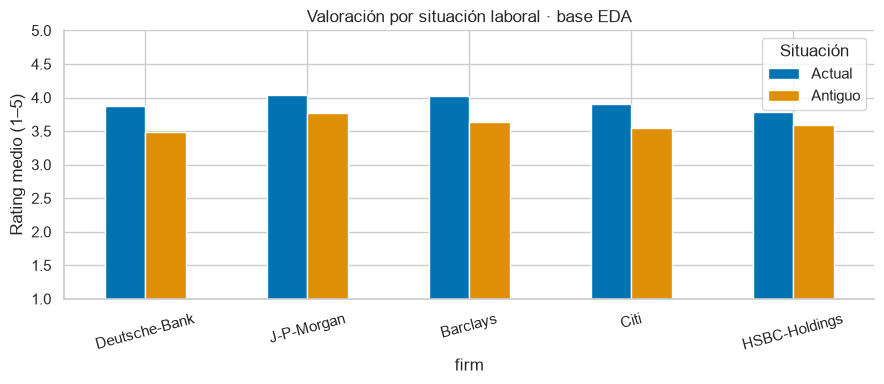

En Deutsche Bank, el rating de antiguos menos el de actuales es **-0.39 puntos sobre 5**. La tabla muestra cuántas reseñas respaldan cada media. Esta diferencia invita a contrastar experiencias en entrevistas de permanencia y salida, sin asumir un motivo de dimisión. Más adelante compararemos los asuntos que menciona cada colectivo; primero comprobamos la evolución del contexto.

In [5]:
estado_eda = eda.groupby(['firm', 'situacion']).agg(reseñas=('review_id', 'size'),
                rating_n=('overall_rating', 'count'), rating_medio=('overall_rating', 'mean')).reindex(FIRMS, level=0)
tabla(estado_eda)
p = estado_eda['rating_medio'].unstack().reindex(FIRMS)
ax = p.plot.bar(rot=15, ylim=(1, 5), ylabel='Rating medio (1–5)', title='Valoración por situación laboral · base EDA')
ax.legend(title='Situación'); plt.tight_layout(); plt.show()
delta_estado = p.loc[TARGET].get('Antiguo', np.nan) - p.loc[TARGET].get('Actual', np.nan)
narrar(f'En Deutsche Bank, el rating de antiguos menos el de actuales es **{delta_estado:+.2f} puntos sobre 5**. '
       'La tabla muestra cuántas reseñas respaldan cada media. Esta diferencia invita a contrastar experiencias '
       'en entrevistas de permanencia y salida, sin asumir un motivo de dimisión. Más adelante compararemos '
       'los asuntos que menciona cada colectivo; primero comprobamos la evolución del contexto.')

La serie anual ayuda a ver si una media global oculta cambios. Presentamos los recuentos junto al gráfico y dejamos sin línea los periodos con menos de 30 ratings válidos: es una regla de lectura prudente, no una prueba estadística. El primer y último año pueden ser parciales, por lo que sus volúmenes no equivalen a años completos.

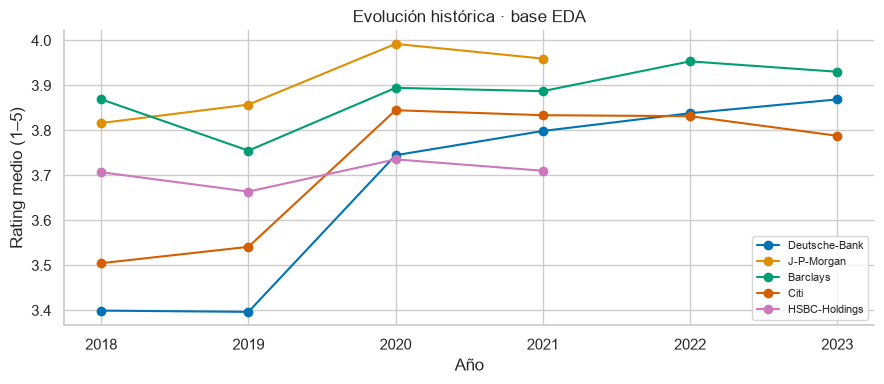

firm,Deutsche-Bank,J-P-Morgan,Barclays,Citi,HSBC-Holdings
Año: número de ratings,,,,,
2018,303.0,904.0,420.0,630.0,570.0
2019,749.0,2578.0,1359.0,1654.0,1717.0
2020,866.0,3510.0,1593.0,2030.0,2091.0
2021,1639.0,4108.0,3254.0,4739.0,2026.0
2022,1551.0,NaN,2706.0,4655.0,NaN
2023,366.0,NaN,531.0,901.0,NaN


Entre 2018 y 2023, la media anual observada de Deutsche Bank pasa de **3.40 a 3.87**. No atribuimos el cambio a políticas concretas: puede variar quién publica, su puesto o su país. **J-P-Morgan y HSBC-Holdings no aportan reseñas en 2022–2023** bajo estos nombres; compararemos también las categorías en el periodo compartido. RRHH debería contrastar los periodos con encuestas internas antes de actuar. El rating nos da contexto, pero necesitamos leer qué se valora y qué se critica.

In [6]:
anual = eda.dropna(subset=['anio']).groupby(['anio', 'firm']).agg(
    rating=('overall_rating', 'mean'), n=('overall_rating', 'count'))
medias_anuales = anual['rating'].where(anual['n'].ge(30)).unstack().reindex(columns=FIRMS)
ax = medias_anuales.plot(marker='o', ylabel='Rating medio (1–5)', xlabel='Año',
                        title='Evolución histórica · base EDA')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
tabla(anual['n'].unstack().reindex(columns=FIRMS).rename_axis('Año: número de ratings'))
t = medias_anuales[TARGET].dropna()
narrar(f'Entre {int(t.index[0])} y {int(t.index[-1])}, la media anual observada de Deutsche Bank pasa '
       f'de **{t.iloc[0]:.2f} a {t.iloc[-1]:.2f}**. No atribuimos el cambio a políticas concretas: '
       'puede variar quién publica, su puesto o su país. **J-P-Morgan y HSBC-Holdings no aportan reseñas en 2022–2023** '
       'bajo estos nombres; compararemos también las categorías en el periodo compartido. RRHH debería contrastar los periodos con '
       'encuestas internas antes de actuar. El rating nos da contexto, pero necesitamos leer qué se valora y qué se critica.')

## 2. Sentimiento en pros y cons: control de calidad.

Un **transformer** es un modelo que interpreta palabras teniendo en cuenta las que las rodean: «no es un buen jefe» no debería leerse igual que «es un buen jefe». Usaremos [DistilBERT SST-2](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english), una versión compacta que permite procesar la muestra incluso en CPU. Está entrenado en inglés y en otro dominio; comprobamos el idioma y ejemplos reales antes de confiar en sus resultados.

Este modelo solo decide **positivo o negativo; no tiene neutral**. Aquí funciona como control de coherencia de los campos pros y cons, no como medición de satisfacción ni de *accuracy*: no contamos con etiquetas humanas de referencia. Nunca usamos el rating como variable objetivo.

Primero detectamos orientativamente el idioma sobre **pros y cons unidos por reseña**, para dar más contexto al detector. Los textos breves pueden parecer otro idioma por error. Mostraremos una muestra de los señalados y no eliminaremos reseñas automáticamente por este detector imperfecto. Esta unión se usa únicamente para comprobar el idioma; sentimiento y temas siguen separados en pros y cons. Esperamos que predomine el tono positivo en pros y el negativo en cons; comprobaremos cuánto se cumple y por qué hay excepciones.

In [7]:
from langdetect import detect, DetectorFactory, LangDetectException
DetectorFactory.seed = SEED
def idioma(texto):
    if len(texto.split()) < 5: return 'Breve/indeterminado'
    try: return detect(texto)
    except LangDetectException: return 'Indeterminado'
nlp['idioma_estimado'] = (nlp.pros + '. ' + nlp.cons).map(idioma)
idiomas = pd.crosstab(nlp.firm, nlp.idioma_estimado).reindex(FIRMS).fillna(0)
idioma_resumen = pd.DataFrame({'reseñas': nlp.groupby('firm').size(),
    'inglés_estimado_n': nlp.idioma_estimado.eq('en').groupby(nlp.firm).sum(),
    'breve_indeterminado_n': nlp.idioma_estimado.isin(['Breve/indeterminado', 'Indeterminado']).groupby(nlp.firm).sum()}).reindex(FIRMS)
idioma_resumen['inglés_estimado_%'] = 100 * idioma_resumen.inglés_estimado_n / idioma_resumen.reseñas
tabla(idioma_resumen)
senialados = nlp.loc[~nlp.idioma_estimado.isin(['en', 'Breve/indeterminado', 'Indeterminado'])]
tabla(senialados[['firm', 'idioma_estimado', 'pros', 'cons']].head(6))
assert nlp.idioma_estimado.eq('en').mean() >= .85, 'Revisar idioma y modelos antes de continuar.'
narrar(f'El detector señala inglés en el **{100 * nlp.idioma_estimado.eq("en").mean():.1f}%** de las reseñas. '
       'Esta comprobación orienta la elección de modelos; no certifica el idioma de cada frase. '
       f'El detector señala **{len(senialados)} casos** para revisar. En la muestra revisada hay un texto claramente alemán '
       'y muchos falsos avisos en frases inglesas breves o repetidas, como «Promotions are not done on time». '
       'Conservamos la muestra para no eliminar textos por un detector imperfecto, pero no interpretamos '
       'individualmente el resultado del texto alemán. La adecuación de los modelos es principalmente al inglés; '
       'un caso de 5.000 representa el 0,02% de la muestra y el 0,1% de Deutsche Bank.')

,reseñas,inglés_estimado_n,breve_indeterminado_n,inglés_estimado_%
firm,,,,
Deutsche-Bank,1000,996,0,99.6
J-P-Morgan,1000,996,0,99.6
Barclays,1000,999,0,99.9
Citi,1000,996,0,99.6
HSBC-Holdings,1000,992,0,99.2


,firm,idioma_estimado,pros,cons
review_id,,,,
361edb48bae53a93,Deutsche-Bank,de,- Sehr gute Benefits - Sehr gute Kantine - Home office möglich - Vermögenswirksame Leistungen,- Teilweise schwierige Prozesse - Langjährige Mitarbeiter beharren auf alte Vorgehensweisen
a7a5bfb0c43b5c3e,Deutsche-Bank,it,Talent Diverse PnL driven motivated Good,None none none none none
9cb4a7cf4fbceb62,Deutsche-Bank,fr,Work environment is quite good.,Promotions are not done on time.
713c1f179b5d5bcb,Deutsche-Bank,nl,Good growth and salary and good management,Pressure jjjjjbbbh huijjb juiii uiiin
14f9aa00f5a1ed6e,J-P-Morgan,so,no good no good no good,"all bad thing, too much work"
27eaec176df81a43,J-P-Morgan,fr,Friendly team environment and management,Facilities are quite old


El detector señala inglés en el **99.6%** de las reseñas. Esta comprobación orienta la elección de modelos; no certifica el idioma de cada frase. El detector señala **21 casos** para revisar. En la muestra revisada hay un texto claramente alemán y muchos falsos avisos en frases inglesas breves o repetidas, como «Promotions are not done on time». Conservamos la muestra para no eliminar textos por un detector imperfecto, pero no interpretamos individualmente el resultado del texto alemán. La adecuación de los modelos es principalmente al inglés; un caso de 5.000 representa el 0,02% de la muestra y el 0,1% de Deutsche Bank.

Procesamos pros y cons por separado, en lotes, conservando el identificador de cada reseña. Los textos se ordenan por longitud solo durante el cálculo para reducir relleno y tiempo en CPU; después se recupera su correspondencia original. `truncation=True` conserva como máximo 512 tokens (fragmentos de palabras), el límite del modelo: una valoración al final de un texto largo puede quedar fuera. Contaremos cuántos textos se recortan.

Guardamos resultados para poder releer la notebook sin repetir el trabajo pesado. Cada caché exige la misma muestra y orden, textos, empresas, revisiones de los modelos, parámetros y versiones; además verificamos una huella del archivo para detectar alteraciones. Los embeddings se guardan por separado para poder revisar la agrupación sin volver a calcular el significado de cada frase. Si algo cambia se recalcula. La descarga del modelo no envía las reseñas a un servicio de inferencia.

In [8]:
import torch
from transformers import pipeline, AutoTokenizer
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = 0 if torch.cuda.is_available() else -1
SENT_MODEL = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
SENT_REV = '714eb0fa89d2f80546fda750413ed43d93601a13'
EMB_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
EMB_REV = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
PAQUETES = ['pandas', 'numpy', 'torch', 'transformers', 'sentence-transformers', 'bertopic',
            'umap-learn', 'hdbscan', 'scikit-learn', 'numba', 'langdetect', 'scipy',
            'llvmlite', 'tokenizers', 'huggingface-hub', 'pyarrow', 'pynndescent']
VERSIONES = {p: version(p) for p in PAQUETES}
CONFIG = dict(empresas=FIRMS, semilla=SEED, muestra=MAX_POR_EMPRESA,
              sentimiento=[SENT_MODEL, SENT_REV], embeddings=[EMB_MODEL, EMB_REV],
              max_tokens=512, lote=32, dispositivo='cuda' if DEVICE == 0 else 'cpu',
              umap=dict(n_neighbors=15, n_components=5, min_dist=0., metric='cosine', random_state=SEED, n_jobs=1),
              hdbscan=dict(min_cluster_size=40, min_samples=10, metric='euclidean', cluster_selection_method='eom'),
              vectorizador=dict(stop_words='english', ngram_range=[1, 2], min_df=2), versiones=VERSIONES,
              python=platform.python_version(), limpieza='espacios_y_saltos_v1', esquema_cache=2,
              embedding_opciones=dict(batch_size=64, normalize_embeddings=True, max_seq_length=256),
              topic_opciones=dict(top_n_words=8, calculate_probabilities=False,
                  prediction_data=True, core_dist_n_jobs=1, language=None),
              ctfidf=dict(bm25_weighting=False, reduce_frequent_words=False))
huella_datos = hashlib.sha256(nlp[['review_id', 'firm', 'pros', 'cons']].to_json(orient='records', force_ascii=False).encode()).hexdigest()
MANIFIESTO = dict(config=CONFIG, datos_sha256=huella_datos)
FIRMA = hashlib.sha256(json.dumps(MANIFIESTO, sort_keys=True).encode()).hexdigest()
RUN = CACHE / FIRMA
RUN.mkdir(exist_ok=True)
ruta_manifest = RUN / 'manifest.json'
if ruta_manifest.exists():
    assert json.loads(ruta_manifest.read_text(encoding='utf-8')) == MANIFIESTO
else:
    ruta_manifest.write_text(json.dumps(MANIFIESTO, ensure_ascii=False, indent=2), encoding='utf-8')
# Cada artefacto tiene una huella propia dentro del manifiesto de esta ejecución.
registro_path = RUN / 'artefactos.json'
registro = json.loads(registro_path.read_text(encoding='utf-8')) if registro_path.exists() else {}
def sha_archivo(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()
def registrar(ruta):
    registro[ruta.name] = sha_archivo(ruta)
    registro_path.write_text(json.dumps(registro, indent=2), encoding='utf-8')
def cache_verificada(ruta):
    if not ruta.exists() or ruta.name not in registro:
        return False
    if sha_archivo(ruta) != registro[ruta.name]:
        raise ValueError(f'Caché alterada: {ruta.name}. Retirar ese archivo y recalcular.')
    return True

tokenizer = None
sent_pipe = None
sentimientos = {}
for lado in ['pros', 'cons']:
    datos = nlp.loc[nlp[lado + '_valido'], ['review_id', lado]].copy()
    ruta = RUN / f'sentimiento_{lado}.parquet'
    if cache_verificada(ruta):
        res = pd.read_parquet(ruta)
        assert res.review_id.tolist() == datos.review_id.tolist()
    else:
        if sent_pipe is None:
            tokenizer = AutoTokenizer.from_pretrained(SENT_MODEL, revision=SENT_REV)
            sent_pipe = pipeline('sentiment-analysis', model=SENT_MODEL, tokenizer=tokenizer,
                                 revision=SENT_REV, device=DEVICE)
        longitudes = [len(ids) for ids in tokenizer(datos[lado].tolist(), truncation=False, verbose=False)['input_ids']]
        orden = np.argsort(longitudes, kind='stable')
        textos = datos[lado].iloc[orden].tolist()
        preds_orden = sent_pipe(textos, batch_size=32, truncation=True, max_length=512)
        preds = [None] * len(datos)
        for pos, pred in zip(orden, preds_orden): preds[pos] = pred
        res = pd.DataFrame({'review_id': datos.review_id.to_numpy(),
                            'sentimiento': [p['label'] for p in preds],
                            'confianza': [p['score'] for p in preds],
                            'tokens': longitudes})
        res.to_parquet(ruta, index=False)
        registrar(ruta)
    assert res.review_id.is_unique and len(res) == len(datos)
    assert res.sentimiento.isin(['POSITIVE', 'NEGATIVE']).all()
    assert res.confianza.between(0, 1).all() and res.tokens.gt(0).all()
    sentimientos[lado] = res.set_index('review_id')
    nlp[lado + '_sentimiento'] = nlp.review_id.map(sentimientos[lado].sentimiento)
    nlp[lado + '_confianza'] = nlp.review_id.map(sentimientos[lado].confianza)
    print(f'{lado}: {len(res):,} textos; {(res.tokens > 512).sum()} truncados; dispositivo: {CONFIG["dispositivo"]}')
control = bases[['NLP: reseñas', 'NLP: pros válidos', 'NLP: cons válidos']].copy()
for lado, esperado in [('pros', 'POSITIVE'), ('cons', 'NEGATIVE')]:
    validos = nlp.loc[nlp[lado + '_valido']]
    control[lado + '_coherentes_%'] = 100 * validos[lado + '_sentimiento'].eq(esperado).groupby(validos.firm).mean()
tabla(control)
narrar(f'Los pros de Deutsche Bank son positivos en el **{control.loc[TARGET, "pros_coherentes_%"]:.1f}%** '
       f'y los cons negativos en el **{control.loc[TARGET, "cons_coherentes_%"]:.1f}%** de los textos válidos. '
       'Son porcentajes de coherencia con el campo, **no accuracy**. Una frase como «no tengo quejas» '
       'puede ser positiva dentro de cons sin ser un error. Antes de interpretar los desacuerdos leemos casos concretos.')

pros: 5,000 textos; 0 truncados; dispositivo: cpu
cons: 5,000 textos; 4 truncados; dispositivo: cpu


,NLP: reseñas,NLP: pros válidos,NLP: cons válidos,pros_coherentes_%,cons_coherentes_%
firm,,,,,
Deutsche-Bank,1000,1000,1000,93.2,85.2
J-P-Morgan,1000,1000,1000,93.1,80.1
Barclays,1000,1000,1000,95.3,80.5
Citi,1000,1000,1000,94.0,80.9
HSBC-Holdings,1000,1000,1000,94.0,83.3


Los pros de Deutsche Bank son positivos en el **93.2%** y los cons negativos en el **85.2%** de los textos válidos. Son porcentajes de coherencia con el campo, **no accuracy**. Una frase como «no tengo quejas» puede ser positiva dentro de cons sin ser un error. Antes de interpretar los desacuerdos leemos casos concretos.

In [9]:
# Casos cortos para lectura completa; selección reproducible, no muestra representativa de errores.
discordantes = []
for lado, discordante in [('pros', 'NEGATIVE'), ('cons', 'POSITIVE')]:
    g = nlp.loc[nlp[lado + '_sentimiento'].eq(discordante) & nlp[lado].str.len().between(20, 260)]
    for _, r in g.sort_index().head(4).iterrows():
        discordantes.append(dict(review_id=r.review_id, campo=lado, empresa=r.firm,
            texto=r[lado], etiqueta=discordante, confianza=r[lado + '_confianza']))
discordantes = pd.DataFrame(discordantes)
for _, r in discordantes.iterrows():
    narrar(f'**{r.campo} · {r.empresa} · {r.etiqueta}** (puntuación del modelo {r.confianza:.2f}; '
           f'ID `{r.review_id}`)\n\n> {html.escape(r.texto)}')
discordantes.to_json(RUN / 'discordantes.json', orient='records', force_ascii=False, indent=2)

**pros · Barclays · NEGATIVE** (puntuación del modelo 1.00; ID `0024e8ca2280964b`)

> Nothing is good about this place

**pros · Barclays · NEGATIVE** (puntuación del modelo 1.00; ID `004af18b344df52c`)

> Big brand without optimum use

**pros · J-P-Morgan · NEGATIVE** (puntuación del modelo 0.96; ID `0119dc164b04b9f5`)

> They pay you to get licensed

**pros · Citi · NEGATIVE** (puntuación del modelo 1.00; ID `01b3d4d58fbeee11`)

> The problems facing in engineering are head cracking

**cons · Barclays · POSITIVE** (puntuación del modelo 1.00; ID `0012070b20d1531c`)

> You will work in a highly competitive workplace, so always watch your back.

**cons · Citi · POSITIVE** (puntuación del modelo 0.99; ID `005764a0531ab80a`)

> work life balance, bonus scheme, London management

**cons · Citi · POSITIVE** (puntuación del modelo 0.99; ID `006d87d073d2815a`)

> Sometimes work could be hectic and fast paced.

**cons · HSBC-Holdings · POSITIVE** (puntuación del modelo 0.99; ID `00aa9e9034be74f6`)

> career progression, monotonic nature of work

<!-- DISCORDANTES_REVISADOS -->
En los pros, «Nothing is good about this place» es una crítica real pese al campo donde se escribió; la etiqueta negativa parece coherente con su negación. «Big brand without optimum use» mezcla una ventaja con una crítica. «They pay you to get licensed» describe un beneficio y su etiqueta negativa parece un error del modelo. «The problems facing in engineering are head cracking» admite una lectura de dificultad o reto estimulante: no podemos resolverla solo con el campo.

En los cons, «always watch your back» es una advertencia que el modelo parece pasar por alto al leer «competitive workplace». La enumeración «work life balance, bonus scheme, London management» no expresa por sí sola una polaridad. «hectic and fast paced» puede describir presión o dinamismo. «career progression, monotonic nature of work» mezcla una expresión habitualmente positiva con monotonía; la clase positiva pierde ese matiz. Son interpretaciones propuestas por el asistente para revisar, no etiquetas humanas de referencia.

Los ejemplos muestran que **desacuerdo con el campo y error del modelo no son lo mismo**. Su puntuación tampoco es una probabilidad calibrada de acierto. Para RRHH, este control señala límites de la lectura automática, pero aún no responde **de qué asuntos se habla**. Ese es el objetivo del siguiente apartado.

## 3. Topic modeling.

El control anterior nos dice cómo suenan las frases, pero RRHH necesita saber **de qué hablan**. Un **embedding** representa el significado mediante números: acerca «salario competitivo» y «buena remuneración» aunque usen palabras diferentes. Conservamos [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), adecuado para el inglés predominante y asumible en CPU. Sus entradas se limitan a 256 tokens; contamos los recortes porque pueden perder asuntos al final de textos largos.

BERTopic organiza esta lectura en tres pasos:

1. **UMAP** resume los embeddings en menos coordenadas procurando que los textos parecidos sigan cerca. Es como simplificar un mapa para encontrar zonas, aceptando que se pierde detalle.
2. **HDBSCAN** busca zonas con muchas reseñas próximas y forma grupos; permite dejar fuera los textos que no encajan con claridad. No le imponemos cuántos grupos debe encontrar.
3. **c-TF-IDF** destaca palabras frecuentes dentro de un grupo y menos habituales en los demás. Ayuda a describirlo; esas palabras no son una explicación completa de cada reseña. El vectorizador omite palabras inglesas comunes como «the» o «and» **solo en esta descripción**, no en los textos del transformer. [Documentación del método](https://maartengr.github.io/BERTopic/getting_started/ctfidf/ctfidf.html).

Llamamos **topic** a cada grupo. Ajustamos un modelo con los pros de **todas las empresas juntas** y otro con sus cons: así cada lado comparte temas entre empresas. El topic 3 de pros puede ser distinto del topic 3 de cons; por eso sus mapas de etiquetas son independientes. Esperamos encontrar asuntos de RRHH reconocibles, pero los nombres se decidirán tras leer palabras y ejemplos, no antes.

Conservamos 15 vecinos y cinco coordenadas en UMAP: buscamos relaciones locales sin reducir el análisis a un dibujo en dos dimensiones. `min_cluster_size=40` evita grupos de apenas unas frases; `min_samples=10` exige apoyo de textos cercanos sin pedir que todo el grupo sea idéntico. Aumentar esa exigencia podría dejar más textos fuera. El vectorizador describe palabras y parejas de palabras (como «work life»); `min_df=2` exige presencia en dos grupos de textos agregados para describir temas, lo que limita términos aislados pero puede perder vocabulario específico. Son elecciones exploratorias para obtener temas legibles, no parámetros optimizados con etiquetas humanas. [UMAP](https://maartengr.github.io/BERTopic/getting_started/dim_reduction/dim_reduction.html), [agrupación](https://maartengr.github.io/BERTopic/getting_started/clustering/clustering.html).

Un **outlier**, marcado `-1`, queda como **Sin clasificar**. Puede contener varios asuntos o uno poco frecuente; no significa irrelevancia. Conservamos estos casos en los denominadores. Reunir topics repetidos bajo una categoría de negocio no reasigna outliers ni reentrena el modelo. Tampoco reducir el número de topics resolvería automáticamente esos casos. Guardamos embeddings, asignaciones y ejemplos; cualquier reentrenamiento exige comprobar de nuevo las etiquetas.

In [10]:
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

encoder = None
inventarios, asignaciones = {}, {}
EMB_CACHE = CACHE / 'embeddings'
EMB_CACHE.mkdir(exist_ok=True)
for lado in ['pros', 'cons']:
    datos = nlp.loc[nlp[lado + '_valido'], ['review_id', lado]].copy()
    textos = datos[lado].tolist()
    # Huella independiente del clustering: permite reutilizar embeddings al cambiar UMAP/HDBSCAN.
    emb_config = dict(modelo=[EMB_MODEL, EMB_REV], opciones=CONFIG['embedding_opciones'],
        dispositivo=CONFIG['dispositivo'], python=CONFIG['python'],
        versiones={k: VERSIONES[k] for k in ['numpy', 'torch', 'transformers', 'sentence-transformers',
                                            'tokenizers', 'huggingface-hub']},
        datos_sha256=hashlib.sha256(datos.to_json(orient='records', force_ascii=False).encode()).hexdigest())
    emb_firma = hashlib.sha256(json.dumps(emb_config, sort_keys=True).encode()).hexdigest()
    emb_ruta, emb_meta = EMB_CACHE / (emb_firma + '.npz'), EMB_CACHE / (emb_firma + '.json')
    if emb_ruta.exists() and emb_meta.exists():
        meta = json.loads(emb_meta.read_text(encoding='utf-8'))
        assert meta['config'] == emb_config and meta['archivo_sha256'] == sha_archivo(emb_ruta), 'Embeddings alterados.'
        with np.load(emb_ruta, allow_pickle=False) as guardado:
            assert guardado['review_id'].tolist() == datos.review_id.tolist()
            vectores, tokens_emb = guardado['vectores'], guardado['tokens']
    else:
        if encoder is None:
            encoder = SentenceTransformer(EMB_MODEL, revision=EMB_REV, device='cuda' if DEVICE == 0 else 'cpu')
            encoder.max_seq_length = CONFIG['embedding_opciones']['max_seq_length']
        vectores = encoder.encode(textos, batch_size=64, show_progress_bar=False, normalize_embeddings=True)
        tokens_emb = np.array([len(x) for x in encoder.tokenizer(textos, truncation=False, verbose=False)['input_ids']])
        np.savez_compressed(emb_ruta, vectores=vectores, tokens=tokens_emb,
                            review_id=datos.review_id.to_numpy(dtype=str))
        emb_meta.write_text(json.dumps(dict(config=emb_config, archivo_sha256=sha_archivo(emb_ruta)),
                                       ensure_ascii=False, indent=2), encoding='utf-8')
    assert vectores.shape == (len(datos), 384) and np.isfinite(vectores).all()
    assert len(tokens_emb) == len(datos) and (tokens_emb > 0).all()

    ruta_topics, ruta_info = RUN / f'topics_{lado}.parquet', RUN / f'inventario_{lado}.json'
    if cache_verificada(ruta_topics) and cache_verificada(ruta_info):
        asignacion = pd.read_parquet(ruta_topics)
        assert asignacion.review_id.tolist() == datos.review_id.tolist()
        inventario = json.loads(ruta_info.read_text(encoding='utf-8'))
    else:
        # Con embeddings precalculados, mantener el preprocesado anterior del vectorizador:
        # language=None evita que BERTopic una «work-life» en «worklife» al borrar el guion.
        modelo = BERTopic(embedding_model=None, language=CONFIG['topic_opciones']['language'],
            umap_model=UMAP(**CONFIG['umap']),
            hdbscan_model=HDBSCAN(**CONFIG['hdbscan'], prediction_data=True, core_dist_n_jobs=1),
            vectorizer_model=CountVectorizer(stop_words=CONFIG['vectorizador']['stop_words'],
                ngram_range=tuple(CONFIG['vectorizador']['ngram_range']), min_df=CONFIG['vectorizador']['min_df']),
            ctfidf_model=ClassTfidfTransformer(**CONFIG['ctfidf']),
            top_n_words=CONFIG['topic_opciones']['top_n_words'], calculate_probabilities=False, verbose=False)
        topics, _ = modelo.fit_transform(textos, embeddings=vectores)
        asignacion = pd.DataFrame({'review_id': datos.review_id.to_numpy(), 'topic': topics, 'tokens_emb': tokens_emb})
        inventario = [{'topic': int(t), 'n': int(n),
            'palabras': [p for p, _ in modelo.get_topic(int(t))],
            'ejemplos': (modelo.get_representative_docs(int(t)) or [])[:3]}
            for t, n in pd.Series(topics).value_counts().sort_index().items()]
        asignacion.to_parquet(ruta_topics, index=False)
        ruta_info.write_text(json.dumps(inventario, ensure_ascii=False, indent=2), encoding='utf-8')
        registrar(ruta_topics); registrar(ruta_info)
    assert asignacion.review_id.is_unique and np.array_equal(asignacion.tokens_emb, tokens_emb)
    assert asignacion.topic.value_counts().to_dict() == {x['topic']: x['n'] for x in inventario}
    assert all(e in set(textos) for x in inventario for e in x['ejemplos'])
    inventarios[lado] = inventario
    asignaciones[lado] = asignacion.set_index('review_id')
    nlp[lado + '_topic'] = nlp.review_id.map(asignaciones[lado].topic).astype('Int64')
    print(f'{lado}: {len(inventario) - int(any(i["topic"] == -1 for i in inventario))} topics; '
          f'{int((tokens_emb > 256).sum())} textos recortados para embeddings.')
    inventario_tabla = pd.DataFrame([{'topic': x['topic'], 'n': x['n'], 'palabras': ', '.join(x['palabras'])} for x in inventario])
    detalle_tabla(f'Ver palabras de todos los topics de {lado}', inventario_tabla)

pros: 27 topics; 2 textos recortados para embeddings.


<details><summary>Ver palabras de todos los topics de pros</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>topic</th>
      <th>n</th>
      <th>palabras</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>-1</td>
      <td>1687</td>
      <td>good, benefits, great, culture, work, people, environment, opportunities</td>
    </tr>
    <tr>
      <th>1</th>
      <td>0</td>
      <td>218</td>
      <td>bank, banking, banks, financial, global, global bank, bank work, investment</td>
    </tr>
    <tr>
      <th>2</th>
      <td>1</td>
      <td>217</td>
      <td>place, place work, great place, good place, work, work great, work good, great</td>
    </tr>
    <tr>
      <th>3</th>
      <td>2</td>
      <td>210</td>
      <td>company, company work, good company, great company, work good, work, work great, great</td>
    </tr>
    <tr>
      <th>4</th>
      <td>3</td>
      <td>200</td>
      <td>flexible, flexible working, hours, working, working hours, flexibility, flexible work, schedule</td>
    </tr>
    <tr>
      <th>5</th>
      <td>4</td>
      <td>200</td>
      <td>environment, work environment, office, nice, atmosphere, environment good, friendly, people</td>
    </tr>
    <tr>
      <th>6</th>
      <td>5</td>
      <td>192</td>
      <td>team, great team, good team, teams, team work, team good, great, team great</td>
    </tr>
    <tr>
      <th>7</th>
      <td>6</td>
      <td>184</td>
      <td>balance, work life, life, life balance, good work, work, balance good, balance work</td>
    </tr>
    <tr>
      <th>8</th>
      <td>7</td>
      <td>161</td>
      <td>learning, career, opportunities, learn, training, learn lot, lot, exposure</td>
    </tr>
    <tr>
      <th>9</th>
      <td>8</td>
      <td>155</td>
      <td>global, international, network, opportunities, large, big, company, global network</td>
    </tr>
    <tr>
      <th>10</th>
      <td>9</td>
      <td>149</td>
      <td>benefits, good benefits, great benefits, great, benefits great, good, people, benefit</td>
    </tr>
    <tr>
      <th>11</th>
      <td>10</td>
      <td>148</td>
      <td>pay, salary, benefits, good pay, pay good, good, benefits good, good salary</td>
    </tr>
    <tr>
      <th>12</th>
      <td>11</td>
      <td>114</td>
      <td>work culture, culture, culture good, work, good work, working culture, environment, good</td>
    </tr>
    <tr>
      <th>13</th>
      <td>12</td>
      <td>113</td>
      <td>people, colleagues, people work, nice, nice people, good people, people great, work people</td>
    </tr>
    <tr>
      <th>14</th>
      <td>13</td>
      <td>102</td>
      <td>brand, good brand, strong brand, strong, great brand, brand value, brand recognition, global brand</td>
    </tr>
    <tr>
      <th>15</th>
      <td>14</td>
      <td>101</td>
      <td>pros, good good, okay, think, far, good, ok, think good</td>
    </tr>
    <tr>
      <th>16</th>
      <td>15</td>
      <td>96</td>
      <td>staff, supportive, management, managers, environment, professional, good, support</td>
    </tr>
    <tr>
      <th>17</th>
      <td>16</td>
      <td>91</td>
      <td>culture, balance, life, life balance, work life, culture work, work culture, work</td>
    </tr>
    <tr>
      <th>18</th>
      <td>17</td>
      <td>85</td>
      <td>life balance, work life, balance, life, balance good, work, pay, benefits work</td>
    </tr>
    <tr>
      <th>19</th>
      <td>18</td>
      <td>83</td>
      <td>days, vacation, 401k, leave, maternity, benefits, sick, annual leave</td>
    </tr>
    <tr>
      <th>20</th>
      <td>19</td>
      <td>77</td>
      <td>culture, great culture, good culture, people, nice culture, culture good, culture great, nice</td>
    </tr>
    <tr>
      <th>21</th>
      <td>20</td>
      <td>77</td>
      <td>diversity, diversity inclusion, inclusion, focus, focus diversity, diverse, culture diversity, women</td>
    </tr>
    <tr>
      <th>22</th>
      <td>21</td>
      <td>66</td>
      <td>salary, pay, good salary, environment, nice, decent, good, good environment</td>
    </tr>
    <tr>
      <th>23</th>
      <td>22</td>
      <td>66</td>
      <td>bonus, compensation, bonus good, good compensation, salary, good bonus, compensation good, package</td>
    </tr>
    <tr>
      <th>24</th>
      <td>23</td>
      <td>62</td>
      <td>home, work home, working home, home good, working, flexible, covid, work</td>
    </tr>
    <tr>
      <th>25</th>
      <td>24</td>
      <td>59</td>
      <td>technology, new, technologies, tech, new technologies, latest, learn, new technology</td>
    </tr>
    <tr>
      <th>26</th>
      <td>25</td>
      <td>47</td>
      <td>balance good, life, work life, balance, life balance, work, balance work, good work</td>
    </tr>
    <tr>
      <th>27</th>
      <td>26</td>
      <td>40</td>
      <td>medical, health, benefits, insurance, health insurance, loan, good benefits, great health</td>
    </tr>
  </tbody>
</table></details>

cons: 27 topics; 17 textos recortados para embeddings.


<details><summary>Ver palabras de todos los topics de cons</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>topic</th>
      <th>n</th>
      <th>palabras</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>-1</td>
      <td>1516</td>
      <td>management, work, hours, long, employees, people, working, hr</td>
    </tr>
    <tr>
      <th>1</th>
      <td>0</td>
      <td>651</td>
      <td>cons, think, say, far, good, think cons, place, company</td>
    </tr>
    <tr>
      <th>2</th>
      <td>1</td>
      <td>290</td>
      <td>technology, systems, tech, slow, old, processes, legacy, process</td>
    </tr>
    <tr>
      <th>3</th>
      <td>2</td>
      <td>264</td>
      <td>salary, pay, low, low salary, compared, market, benefits, salary low</td>
    </tr>
    <tr>
      <th>4</th>
      <td>3</td>
      <td>180</td>
      <td>culture, environment, toxic, bad, work culture, work, diversity, people</td>
    </tr>
    <tr>
      <th>5</th>
      <td>4</td>
      <td>161</td>
      <td>bank, banks, banking, compared, investment, like, deutsche, deutsche bank</td>
    </tr>
    <tr>
      <th>6</th>
      <td>5</td>
      <td>157</td>
      <td>promotion, promotions, promoted, difficult, vp, year, hard promoted, slow promotion</td>
    </tr>
    <tr>
      <th>7</th>
      <td>6</td>
      <td>151</td>
      <td>hours, long, long hours, working hours, long working, hours long, working, hours times</td>
    </tr>
    <tr>
      <th>8</th>
      <td>7</td>
      <td>142</td>
      <td>balance, life, work life, life balance, work, balance work, poor work, life work</td>
    </tr>
    <tr>
      <th>9</th>
      <td>8</td>
      <td>139</td>
      <td>bureaucracy, bureaucratic, lots, large, things, lots bureaucracy, slow, change</td>
    </tr>
    <tr>
      <th>10</th>
      <td>9</td>
      <td>137</td>
      <td>politics, political, leadership, office politics, office, senior, favoritism, lack</td>
    </tr>
    <tr>
      <th>11</th>
      <td>10</td>
      <td>133</td>
      <td>management, managers, lack, manager, poor, upper management, upper, terrible</td>
    </tr>
    <tr>
      <th>12</th>
      <td>11</td>
      <td>115</td>
      <td>large, big, company, complex, navigate, large company, size, hierarchy</td>
    </tr>
    <tr>
      <th>13</th>
      <td>12</td>
      <td>113</td>
      <td>career, progression, career progression, career growth, slow career, growth, opportunities, slow</td>
    </tr>
    <tr>
      <th>14</th>
      <td>13</td>
      <td>107</td>
      <td>stressful, boring, timings, work, busy, monotonous, shift, fast paced</td>
    </tr>
    <tr>
      <th>15</th>
      <td>14</td>
      <td>85</td>
      <td>team, teams, depends, depends team, balance, life balance, work life, communication</td>
    </tr>
    <tr>
      <th>16</th>
      <td>15</td>
      <td>82</td>
      <td>bonus, increment, bonuses, low, annual, salary, pay, low bonus</td>
    </tr>
    <tr>
      <th>17</th>
      <td>16</td>
      <td>78</td>
      <td>mobility, internal mobility, upward, upward mobility, hard, moving, opportunities, internal</td>
    </tr>
    <tr>
      <th>18</th>
      <td>17</td>
      <td>59</td>
      <td>training, learning, learn, new, learn training, freshers, learning curve, curve</td>
    </tr>
    <tr>
      <th>19</th>
      <td>18</td>
      <td>59</td>
      <td>growth, slow, opportunities, slow growth, grow, growth opportunities, limited growth, growth growth</td>
    </tr>
    <tr>
      <th>20</th>
      <td>19</td>
      <td>54</td>
      <td>customers, customer, sales, targets, target, service, pressure, clients</td>
    </tr>
    <tr>
      <th>21</th>
      <td>20</td>
      <td>54</td>
      <td>hsbc, barclays, data, staff, cons, years, year, uk</td>
    </tr>
    <tr>
      <th>22</th>
      <td>21</td>
      <td>52</td>
      <td>workload, load, work load, heavy, heavy workload, high, work, high work</td>
    </tr>
    <tr>
      <th>23</th>
      <td>22</td>
      <td>47</td>
      <td>layoffs, security, job security, job, lay, offs, years, frequent</td>
    </tr>
    <tr>
      <th>24</th>
      <td>23</td>
      <td>46</td>
      <td>change, changes, management, change management, strategy, management changes, restructuring, uncertainty</td>
    </tr>
    <tr>
      <th>25</th>
      <td>24</td>
      <td>45</td>
      <td>pressure, work pressure, high pressure, high, pressure work, work, pressure bad, long</td>
    </tr>
    <tr>
      <th>26</th>
      <td>25</td>
      <td>43</td>
      <td>challenging, work, challenges, work work, work little, time, work challenging, work hard</td>
    </tr>
    <tr>
      <th>27</th>
      <td>26</td>
      <td>40</td>
      <td>life, hours, long, balance long, work life, hours work, balance, life balance</td>
    </tr>
  </tbody>
</table></details>

Los números de topic son etiquetas técnicas. Para RRHH reunimos los grupos en un marco común de categorías para pros y cons. Leemos palabras y ejemplos representativos antes de proponer cada etiqueta; **esta revisión es del asistente, y la validación humana conjunta sigue pendiente**. Cada texto recibe una sola categoría dominante: puede mencionar más asuntos que no queden contabilizados.

El diccionario siguiente es explícito y editable. Los temas vagos se conservan como «Valoración general» y las expresiones sin queja concreta se separan de los problemas laborales. Ninguna de esas categorías, ni «Sin clasificar», generará automáticamente una recomendación. Los grupos repetidos de conciliación se suman en una sola categoría sin contar dos veces ninguna reseña. Los grupos heterogéneos quedan como «Otros temas»: preferimos reconocer esa incertidumbre a imponer una etiqueta. La revisión busca categorías útiles, no un número de topics vistoso. Si se cambian datos, modelos o parámetros, se detiene la aplicación del diccionario hasta revisar los nuevos grupos.

In [11]:
# Propuestas tras leer palabras y ejemplos. Editar aquí al validar con RRHH.
# Las etiquetas dependen del contenido de los topics, no de la versión de Python.
HUELLA_TOPICS_REVISADOS = '42a3fa617187f8abf55e4efcba06b0033d4761b425485affb9a61682f9fb95a9'
TOPIC_A_CATEGORIA = {'pros': {-1: 'Sin clasificar',
          0: 'Marca y alcance internacional',
          1: 'Valoración general',
          2: 'Valoración general',
          3: 'Conciliación',
          4: 'Cultura',
          5: 'Cultura',
          6: 'Conciliación',
          7: 'Carrera',
          8: 'Marca y alcance internacional',
          9: 'Compensación',
          10: 'Compensación',
          11: 'Cultura',
          12: 'Cultura',
          13: 'Marca y alcance internacional',
          14: 'Valoración general',
          15: 'Cultura',
          16: 'Conciliación',
          17: 'Conciliación',
          18: 'Compensación',
          19: 'Cultura',
          20: 'Cultura',
          21: 'Compensación',
          22: 'Compensación',
          23: 'Conciliación',
          24: 'Procesos y tecnología',
          25: 'Conciliación',
          26: 'Compensación'},
 'cons': {-1: 'Sin clasificar',
          0: 'Sin quejas concretas',
          1: 'Procesos y tecnología',
          2: 'Compensación',
          3: 'Cultura',
          4: 'Otros temas',
          5: 'Carrera',
          6: 'Conciliación',
          7: 'Conciliación',
          8: 'Procesos y tecnología',
          9: 'Dirección',
          10: 'Dirección',
          11: 'Procesos y tecnología',
          12: 'Carrera',
          13: 'Otros temas',
          14: 'Otros temas',
          15: 'Compensación',
          16: 'Carrera',
          17: 'Carrera',
          18: 'Carrera',
          19: 'Conciliación',
          20: 'Otros temas',
          21: 'Conciliación',
          22: 'Estabilidad laboral',
          23: 'Dirección',
          24: 'Conciliación',
          25: 'Otros temas',
          26: 'Conciliación'}}

# Validar también el corpus y los parámetros revisados; el entorno no define las etiquetas.
DATOS_REVISADOS = '0f7112564e35cbdaf7302976cb47f592ff3c12819ff1d085f48dec790b3dba51'
CONFIG_TOPICS_REVISADA = {'embeddings': ['sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'], 'umap': {'n_neighbors': 15, 'n_components': 5, 'min_dist': 0.0, 'metric': 'cosine', 'random_state': 42, 'n_jobs': 1}, 'hdbscan': {'min_cluster_size': 40, 'min_samples': 10, 'metric': 'euclidean', 'cluster_selection_method': 'eom'}, 'vectorizador': {'stop_words': 'english', 'ngram_range': [1, 2], 'min_df': 2}, 'embedding_opciones': {'batch_size': 64, 'normalize_embeddings': True, 'max_seq_length': 256}, 'topic_opciones': {'top_n_words': 8, 'calculate_probabilities': False, 'prediction_data': True, 'core_dist_n_jobs': 1, 'language': None}, 'ctfidf': {'bm25_weighting': False, 'reduce_frequent_words': False}}
assert huella_datos == DATOS_REVISADOS, 'Muestra nueva: revisar etiquetas y ejemplos.'
assert {k: CONFIG[k] for k in CONFIG_TOPICS_REVISADA} == CONFIG_TOPICS_REVISADA, 'Modelo o parámetros nuevos: revisar etiquetas.'
huella_topics_actual = hashlib.sha256(
    json.dumps(inventarios, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
assert huella_topics_actual == HUELLA_TOPICS_REVISADOS, (
    'Los topics han cambiado: revisar sus ejemplos y actualizar el diccionario y su huella.')
for lado in ['pros', 'cons']:
    observados = set(nlp[lado + '_topic'].dropna().astype(int))
    assert observados == set(TOPIC_A_CATEGORIA[lado]), 'Faltan etiquetas o el diccionario pertenece a otros topics.'
    assert TOPIC_A_CATEGORIA[lado].get(-1, 'Sin clasificar') == 'Sin clasificar'
    nlp[lado + '_categoria'] = nlp[lado + '_topic'].map(TOPIC_A_CATEGORIA[lado])
    assert nlp.loc[nlp[lado + '_valido'], lado + '_categoria'].notna().all()
CATEGORIAS = sorted(set().union(*[set(m.values()) for m in TOPIC_A_CATEGORIA.values()]))
NO_ACCION = {'Sin clasificar', 'Sin quejas concretas', 'Valoración general', 'Otros temas'}
CATEGORIAS_NEGOCIO = [c for c in CATEGORIAS if c not in NO_ACCION]
filas = []
for lado, inventario in inventarios.items():
    for x in inventario:
        filas.append({'campo': lado, 'topic': x['topic'], 'n': x['n'],
            'categoría propuesta': TOPIC_A_CATEGORIA[lado][x['topic']],
            'palabras': ', '.join(x['palabras'][:5])})
display(Markdown('<details><summary>Ver todas las etiquetas propuestas y sus recuentos</summary>' +
                pd.DataFrame(filas).to_html(index=False) + '</details>'))

<details><summary>Ver todas las etiquetas propuestas y sus recuentos</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>campo</th>
      <th>topic</th>
      <th>n</th>
      <th>categoría propuesta</th>
      <th>palabras</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>pros</td>
      <td>-1</td>
      <td>1687</td>
      <td>Sin clasificar</td>
      <td>good, benefits, great, culture, work</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>0</td>
      <td>218</td>
      <td>Marca y alcance internacional</td>
      <td>bank, banking, banks, financial, global</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>1</td>
      <td>217</td>
      <td>Valoración general</td>
      <td>place, place work, great place, good place, work</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>2</td>
      <td>210</td>
      <td>Valoración general</td>
      <td>company, company work, good company, great company, work good</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>3</td>
      <td>200</td>
      <td>Conciliación</td>
      <td>flexible, flexible working, hours, working, working hours</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>4</td>
      <td>200</td>
      <td>Cultura</td>
      <td>environment, work environment, office, nice, atmosphere</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>5</td>
      <td>192</td>
      <td>Cultura</td>
      <td>team, great team, good team, teams, team work</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>6</td>
      <td>184</td>
      <td>Conciliación</td>
      <td>balance, work life, life, life balance, good work</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>7</td>
      <td>161</td>
      <td>Carrera</td>
      <td>learning, career, opportunities, learn, training</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>8</td>
      <td>155</td>
      <td>Marca y alcance internacional</td>
      <td>global, international, network, opportunities, large</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>9</td>
      <td>149</td>
      <td>Compensación</td>
      <td>benefits, good benefits, great benefits, great, benefits great</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>10</td>
      <td>148</td>
      <td>Compensación</td>
      <td>pay, salary, benefits, good pay, pay good</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>11</td>
      <td>114</td>
      <td>Cultura</td>
      <td>work culture, culture, culture good, work, good work</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>12</td>
      <td>113</td>
      <td>Cultura</td>
      <td>people, colleagues, people work, nice, nice people</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>13</td>
      <td>102</td>
      <td>Marca y alcance internacional</td>
      <td>brand, good brand, strong brand, strong, great brand</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>14</td>
      <td>101</td>
      <td>Valoración general</td>
      <td>pros, good good, okay, think, far</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>15</td>
      <td>96</td>
      <td>Cultura</td>
      <td>staff, supportive, management, managers, environment</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>16</td>
      <td>91</td>
      <td>Conciliación</td>
      <td>culture, balance, life, life balance, work life</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>17</td>
      <td>85</td>
      <td>Conciliación</td>
      <td>life balance, work life, balance, life, balance good</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>18</td>
      <td>83</td>
      <td>Compensación</td>
      <td>days, vacation, 401k, leave, maternity</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>19</td>
      <td>77</td>
      <td>Cultura</td>
      <td>culture, great culture, good culture, people, nice culture</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>20</td>
      <td>77</td>
      <td>Cultura</td>
      <td>diversity, diversity inclusion, inclusion, focus, focus diversity</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>21</td>
      <td>66</td>
      <td>Compensación</td>
      <td>salary, pay, good salary, environment, nice</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>22</td>
      <td>66</td>
      <td>Compensación</td>
      <td>bonus, compensation, bonus good, good compensation, salary</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>23</td>
      <td>62</td>
      <td>Conciliación</td>
      <td>home, work home, working home, home good, working</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>24</td>
      <td>59</td>
      <td>Procesos y tecnología</td>
      <td>technology, new, technologies, tech, new technologies</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>25</td>
      <td>47</td>
      <td>Conciliación</td>
      <td>balance good, life, work life, balance, life balance</td>
    </tr>
    <tr>
      <td>pros</td>
      <td>26</td>
      <td>40</td>
      <td>Compensación</td>
      <td>medical, health, benefits, insurance, health insurance</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>-1</td>
      <td>1516</td>
      <td>Sin clasificar</td>
      <td>management, work, hours, long, employees</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>0</td>
      <td>651</td>
      <td>Sin quejas concretas</td>
      <td>cons, think, say, far, good</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>1</td>
      <td>290</td>
      <td>Procesos y tecnología</td>
      <td>technology, systems, tech, slow, old</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>2</td>
      <td>264</td>
      <td>Compensación</td>
      <td>salary, pay, low, low salary, compared</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>3</td>
      <td>180</td>
      <td>Cultura</td>
      <td>culture, environment, toxic, bad, work culture</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>4</td>
      <td>161</td>
      <td>Otros temas</td>
      <td>bank, banks, banking, compared, investment</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>5</td>
      <td>157</td>
      <td>Carrera</td>
      <td>promotion, promotions, promoted, difficult, vp</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>6</td>
      <td>151</td>
      <td>Conciliación</td>
      <td>hours, long, long hours, working hours, long working</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>7</td>
      <td>142</td>
      <td>Conciliación</td>
      <td>balance, life, work life, life balance, work</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>8</td>
      <td>139</td>
      <td>Procesos y tecnología</td>
      <td>bureaucracy, bureaucratic, lots, large, things</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>9</td>
      <td>137</td>
      <td>Dirección</td>
      <td>politics, political, leadership, office politics, office</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>10</td>
      <td>133</td>
      <td>Dirección</td>
      <td>management, managers, lack, manager, poor</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>11</td>
      <td>115</td>
      <td>Procesos y tecnología</td>
      <td>large, big, company, complex, navigate</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>12</td>
      <td>113</td>
      <td>Carrera</td>
      <td>career, progression, career progression, career growth, slow career</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>13</td>
      <td>107</td>
      <td>Otros temas</td>
      <td>stressful, boring, timings, work, busy</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>14</td>
      <td>85</td>
      <td>Otros temas</td>
      <td>team, teams, depends, depends team, balance</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>15</td>
      <td>82</td>
      <td>Compensación</td>
      <td>bonus, increment, bonuses, low, annual</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>16</td>
      <td>78</td>
      <td>Carrera</td>
      <td>mobility, internal mobility, upward, upward mobility, hard</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>17</td>
      <td>59</td>
      <td>Carrera</td>
      <td>training, learning, learn, new, learn training</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>18</td>
      <td>59</td>
      <td>Carrera</td>
      <td>growth, slow, opportunities, slow growth, grow</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>19</td>
      <td>54</td>
      <td>Conciliación</td>
      <td>customers, customer, sales, targets, target</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>20</td>
      <td>54</td>
      <td>Otros temas</td>
      <td>hsbc, barclays, data, staff, cons</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>21</td>
      <td>52</td>
      <td>Conciliación</td>
      <td>workload, load, work load, heavy, heavy workload</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>22</td>
      <td>47</td>
      <td>Estabilidad laboral</td>
      <td>layoffs, security, job security, job, lay</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>23</td>
      <td>46</td>
      <td>Dirección</td>
      <td>change, changes, management, change management, strategy</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>24</td>
      <td>45</td>
      <td>Conciliación</td>
      <td>pressure, work pressure, high pressure, high, pressure work</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>25</td>
      <td>43</td>
      <td>Otros temas</td>
      <td>challenging, work, challenges, work work, work little</td>
    </tr>
    <tr>
      <td>cons</td>
      <td>26</td>
      <td>40</td>
      <td>Conciliación</td>
      <td>life, hours, long, balance long, work life</td>
    </tr>
  </tbody>
</table></details>

**Ejemplos leídos y criterio de agrupación.** Las citas siguientes proceden de los textos representativos reales; se conservan en su idioma original. La etiqueta resume el asunto dominante, no garantiza homogeneidad de todo el grupo.

| Categoría propuesta | Ejemplo real y topic | Por qué la proponemos |
|---|---|---|
| Compensación | Pros 10: «Pay was good. Benefits were good.»; cons 15: «No bonus or increment for 3 years» | Sueldo, beneficios y variable forman parte de la retribución. Incluimos seguros y permisos del pros 18 y 26 por su presentación como beneficios; los permisos también podrían leerse como conciliación. |
| Conciliación | Pros 6: «work life balance and more»; cons 26: «long working hours and no work life balance» | Agrupamos flexibilidad, horarios y carga. Cons 19 incluye presión comercial y clientes: revisar si merece una categoría propia. |
| Cultura | Pros 12: «Nice people to work with»; cons 3: «Mistreatment by directors above you. Toxic work culture.» | Compañeros, ambiente e inclusión. Pros 15 se asigna aquí por el apoyo y trato del equipo, aunque menciona dirección. |
| Carrera | Pros 7: «Good training system. Professional, learn a lot»; cons 12: «No mapped career progression in place» | Aprendizaje, promoción y movilidad son partes de la trayectoria profesional. |
| Dirección | Cons 10: «management is not always forthcoming»; cons 23: «Top management changes and restructuring» | Gestión, política interna y cambios de estrategia. Cons 9 (política interna) limita con cultura y debe validarse. |
| Procesos y tecnología | Pros 24: «Open to adopting new technologies»; cons 8: «There is too much Bureaucracy» | Herramientas y trámites afectan a cómo se realiza el trabajo; unimos tecnología heredada y fricción organizativa. |
| Marca y alcance internacional | Pros 8: «Global Company and international opportunities»; pros 13: «Decent brand name and image» | Prestigio y escala internacional; algunos textos de los topics 0 y 8 también hablan de carrera. |
| Estabilidad laboral | Cons 22: «job security, lay-off and off-shoring» | Aparece un asunto distinto: seguridad del empleo. Que la categoría no emerja en pros no demuestra que nadie la valore. |

**Decisiones que conviene revisar juntos.** Pros 16 mezcla cultura y conciliación («Work life balance, mixed culture»); proponemos conciliación por el patrón común de sus ejemplos. Pros 14 incluye «no pros at all»: queda en «Valoración general», no se cuenta como fortaleza. Cons 0 se propone como «Sin quejas concretas» por frases como «there are no cons I can think of». No usamos la ausencia de queja como prueba de una buena experiencia.

Los topics cons 4 y 20 parecían «sin quejas» en sus representantes, pero al leer seis reseñas aleatorias por grupo encontramos también «low bonus compared to other banks» y críticas a sistemas antiguos. Por eso los conservamos como **Otros temas**, junto con los grupos 13, 14 y 25, que mezclan estrés, monotonía, diferencias entre equipos y retos laborales. No forzamos esas combinaciones a una palanca de RRHH.

Los outliers contienen también reseñas extensas con varios asuntos (por ejemplo, salario, carga y apoyo del responsable en el mismo texto). La falta de clasificación no equivale a irrelevancia. Además, cero textos en una categoría significa **cero asignaciones dominantes bajo este modelo**, no ausencia de menciones: es especialmente importante al comparar dirección, estabilidad y marca, que no tienen grupos específicos en ambos lados.

In [12]:
cobertura_topics = bases[['NLP: reseñas', 'NLP: pros válidos', 'NLP: cons válidos']].copy()
for lado in ['pros', 'cons']:
    validos = nlp.loc[nlp[lado + '_valido']]
    cobertura_topics[lado + '_válidos_%'] = 100 * validos.groupby('firm').size() / nlp.groupby('firm').size()
    cobertura_topics[lado + '_sin_clasificar_%'] = 100 * validos[lado + '_topic'].eq(-1).groupby(validos.firm).mean()
tabla(cobertura_topics)
narrar(f'En Deutsche Bank quedan sin clasificar el **{cobertura_topics.loc[TARGET, "pros_sin_clasificar_%"]:.1f}%** '
       f'de los pros válidos y el **{cobertura_topics.loc[TARGET, "cons_sin_clasificar_%"]:.1f}%** de los cons válidos. '
       'Es un límite de cobertura temática, no ausencia de fortalezas o problemas. Los mantenemos en los denominadores '
       'para no inflar artificialmente el peso de los temas que sí interpretamos. Con ese marco común pasamos a la comparación empresarial.')

,NLP: reseñas,NLP: pros válidos,NLP: cons válidos,pros_válidos_%,pros_sin_clasificar_%,cons_válidos_%,cons_sin_clasificar_%
firm,,,,,,,
Deutsche-Bank,1000,1000,1000,100.0,33.3,100.0,29.6
J-P-Morgan,1000,1000,1000,100.0,36.2,100.0,29.2
Barclays,1000,1000,1000,100.0,33.8,100.0,29.2
Citi,1000,1000,1000,100.0,32.7,100.0,32.8
HSBC-Holdings,1000,1000,1000,100.0,32.7,100.0,30.8


En Deutsche Bank quedan sin clasificar el **33.3%** de los pros válidos y el **29.6%** de los cons válidos. Es un límite de cobertura temática, no ausencia de fortalezas o problemas. Los mantenemos en los denominadores para no inflar artificialmente el peso de los temas que sí interpretamos. Con ese marco común pasamos a la comparación empresarial.

## 4. Comparación con peers.

La pregunta ahora es qué distingue a Deutsche Bank. Para cada empresa, el **% pros** divide los textos de una categoría entre todos sus pros válidos en la muestra; el **% cons** hace lo mismo con los cons válidos. Cada reparto suma 100% incluyendo «Sin clasificar» y las categorías sin problema concreto. Los vacíos se excluyen y su cobertura se ha mostrado arriba. Los dos denominadores pueden diferir, así que el balance es una comparación de proporciones, no un recuento de personas satisfechas menos insatisfechas.

El **balance neto = % pros − % cons**, en puntos porcentuales (pp). El **gap = balance de Deutsche Bank − balance medio de los cuatro peers**. Por ejemplo, si una categoría aparece en el 20% de pros y el 30% de cons, su balance es −10 pp; si el balance de los peers es −4 pp, el gap es −6 pp: desventaja relativa de 6 puntos. Es solo un ejemplo didáctico.

Usamos la **media simple de las métricas de las cuatro empresas**, para que cada competidor tenga el mismo peso aunque tenga más reseñas válidas. **0%** significa que hay textos válidos pero ninguno asignado a esa categoría; **— / NaN** significa que falta un denominador y no se puede calcular. Una ausencia de topic específico en pros no demuestra ausencia de opiniones favorables: dirección y estabilidad requieren esa cautela. Estos porcentajes son relativos: si baja el peso de una queja sube el de otras, aunque no hayan empeorado. Un balance negativo por sí solo no demuestra un problema grave, y un gap negativo no demuestra causalidad ni significación estadística.

,Pros DB %,Pros peers %,Cons DB %,Cons peers %,Balance DB pp,Balance peers pp,Gap pp
Compensación,9.3,11.48,8.5,6.52,0.8,4.95,-4.15
Carrera,2.4,3.42,10.3,9.07,-7.9,-5.65,-2.25
Dirección,0.0,0.00,7.0,6.15,-7.0,-6.15,-0.85
Procesos y tecnología,1.7,1.05,12.0,10.60,-10.3,-9.55,-0.75
Estabilidad laboral,0.0,0.00,1.2,0.88,-1.2,-0.88,-0.32
Marca y alcance internacional,9.3,9.55,0.0,0.00,9.3,9.55,-0.25
Cultura,20.8,16.53,3.9,3.53,16.9,13.00,3.90
Conciliación,15.3,12.90,7.1,10.32,8.2,2.58,5.62


<details><summary>Ver porcentajes y balances de las cinco empresas</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th></th>
      <th>pros_%</th>
      <th>cons_%</th>
      <th>balance_pp</th>
    </tr>
    <tr>
      <th>empresa</th>
      <th>categoría</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th rowspan="12" valign="top">Deutsche-Bank</th>
      <th>Carrera</th>
      <td>2.4</td>
      <td>10.3</td>
      <td>-7.9</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>9.3</td>
      <td>8.5</td>
      <td>0.8</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>15.3</td>
      <td>7.1</td>
      <td>8.2</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>20.8</td>
      <td>3.9</td>
      <td>16.9</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>0.0</td>
      <td>7.0</td>
      <td>-7.0</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>0.0</td>
      <td>1.2</td>
      <td>-1.2</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>9.3</td>
      <td>0.0</td>
      <td>9.3</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>0.0</td>
      <td>7.2</td>
      <td>-7.2</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>1.7</td>
      <td>12.0</td>
      <td>-10.3</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>33.3</td>
      <td>29.6</td>
      <td>3.7</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>0.0</td>
      <td>13.2</td>
      <td>-13.2</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>7.9</td>
      <td>0.0</td>
      <td>7.9</td>
    </tr>
    <tr>
      <th rowspan="12" valign="top">J-P-Morgan</th>
      <th>Carrera</th>
      <td>3.7</td>
      <td>9.3</td>
      <td>-5.6</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>12.2</td>
      <td>6.5</td>
      <td>5.7</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>8.5</td>
      <td>12.0</td>
      <td>-3.5</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>16.1</td>
      <td>3.0</td>
      <td>13.1</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>0.0</td>
      <td>6.5</td>
      <td>-6.5</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>0.0</td>
      <td>0.9</td>
      <td>-0.9</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>9.0</td>
      <td>0.0</td>
      <td>9.0</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>0.0</td>
      <td>6.9</td>
      <td>-6.9</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>2.1</td>
      <td>9.2</td>
      <td>-7.1</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>36.2</td>
      <td>29.2</td>
      <td>7.0</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>0.0</td>
      <td>16.5</td>
      <td>-16.5</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>12.2</td>
      <td>0.0</td>
      <td>12.2</td>
    </tr>
    <tr>
      <th rowspan="12" valign="top">Barclays</th>
      <th>Carrera</th>
      <td>2.7</td>
      <td>9.2</td>
      <td>-6.5</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>9.3</td>
      <td>5.2</td>
      <td>4.1</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>17.5</td>
      <td>7.6</td>
      <td>9.9</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>18.6</td>
      <td>3.4</td>
      <td>15.2</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>0.0</td>
      <td>6.8</td>
      <td>-6.8</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>0.0</td>
      <td>0.8</td>
      <td>-0.8</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>4.5</td>
      <td>0.0</td>
      <td>4.5</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>0.0</td>
      <td>11.3</td>
      <td>-11.3</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>0.6</td>
      <td>11.5</td>
      <td>-10.9</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>33.8</td>
      <td>29.2</td>
      <td>4.6</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>0.0</td>
      <td>15.0</td>
      <td>-15.0</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>13.0</td>
      <td>0.0</td>
      <td>13.0</td>
    </tr>
    <tr>
      <th rowspan="12" valign="top">Citi</th>
      <th>Carrera</th>
      <td>3.9</td>
      <td>7.7</td>
      <td>-3.8</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>14.2</td>
      <td>6.9</td>
      <td>7.3</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>12.0</td>
      <td>13.6</td>
      <td>-1.6</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>15.0</td>
      <td>4.2</td>
      <td>10.8</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>0.0</td>
      <td>5.5</td>
      <td>-5.5</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>0.0</td>
      <td>0.5</td>
      <td>-0.5</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>11.7</td>
      <td>0.0</td>
      <td>11.7</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>0.0</td>
      <td>9.1</td>
      <td>-9.1</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>0.9</td>
      <td>9.2</td>
      <td>-8.3</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>32.7</td>
      <td>32.8</td>
      <td>-0.1</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>0.0</td>
      <td>10.5</td>
      <td>-10.5</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>9.6</td>
      <td>0.0</td>
      <td>9.6</td>
    </tr>
    <tr>
      <th rowspan="12" valign="top">HSBC-Holdings</th>
      <th>Carrera</th>
      <td>3.4</td>
      <td>10.1</td>
      <td>-6.7</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>10.2</td>
      <td>7.5</td>
      <td>2.7</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>13.6</td>
      <td>8.1</td>
      <td>5.5</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>16.4</td>
      <td>3.5</td>
      <td>12.9</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>0.0</td>
      <td>5.8</td>
      <td>-5.8</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>0.0</td>
      <td>1.3</td>
      <td>-1.3</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>13.0</td>
      <td>0.0</td>
      <td>13.0</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>0.0</td>
      <td>10.5</td>
      <td>-10.5</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>0.6</td>
      <td>12.5</td>
      <td>-11.9</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>32.7</td>
      <td>30.8</td>
      <td>1.9</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>0.0</td>
      <td>9.9</td>
      <td>-9.9</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>10.1</td>
      <td>0.0</td>
      <td>10.1</td>
    </tr>
  </tbody>
</table></details>

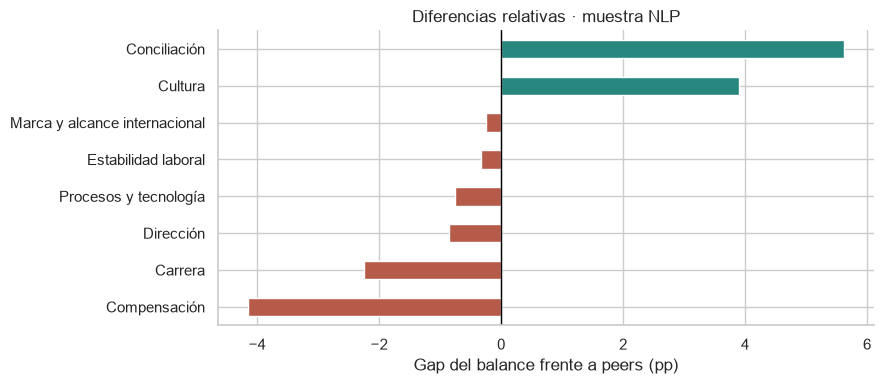

La mayor desventaja temática observada es **Compensación (-4.1 pp)**; el mayor gap es **Conciliación (+5.6 pp)**. Para decidir si son prioridades de RRHH falta comprobar dos cosas: si dependen del distinto periodo disponible y si quienes mencionan esas quejas también valoran peor a la empresa.

**Carrera es un asunto compartido:** aparece en el 10.3% de los cons de Deutsche Bank y en el 9.1% como media de peers. Su gap de -2.25 pp resume tanto críticas como reconocimientos; no implica que el problema sea exclusivo del banco. La tabla permite distinguir frecuencia sectorial y desventaja propia antes de priorizar.

In [13]:
def distribucion(datos, lado):
    validos = datos.loc[datos[lado + '_valido']]
    denominador = validos.groupby('firm').size().reindex(FIRMS, fill_value=0)
    recuento = pd.crosstab(validos.firm, validos[lado + '_categoria']).reindex(
        index=FIRMS, columns=CATEGORIAS, fill_value=0)
    return recuento.div(denominador.replace(0, np.nan), axis=0) * 100
pct_pros, pct_cons = distribucion(nlp, 'pros'), distribucion(nlp, 'cons')
balance = pct_pros - pct_cons
balance_peers = balance.loc[PEERS].mean(axis=0, skipna=False)
gap = balance.loc[TARGET] - balance_peers
comparacion = pd.DataFrame({'pros_TARGET_%': pct_pros.loc[TARGET], 'cons_TARGET_%': pct_cons.loc[TARGET],
    'pros_peers_%': pct_pros.loc[PEERS].mean(skipna=False),
    'cons_peers_%': pct_cons.loc[PEERS].mean(skipna=False),
    'balance_TARGET_pp': balance.loc[TARGET], 'balance_peers_pp': balance_peers, 'gap_pp': gap}).sort_values('gap_pp')
# Tabla completa por empresa y categoría; plegada para no interrumpir la lectura.
detalle = pd.concat({'pros_%': pct_pros.stack(), 'cons_%': pct_cons.stack(), 'balance_pp': balance.stack()}, axis=1)
detalle.index.names = ['empresa', 'categoría']
tabla(comparacion.loc[comparacion.index.isin(CATEGORIAS_NEGOCIO),
    ['pros_TARGET_%', 'pros_peers_%', 'cons_TARGET_%', 'cons_peers_%', 'balance_TARGET_pp', 'balance_peers_pp', 'gap_pp']].rename(
    columns={'pros_TARGET_%': 'Pros DB %', 'pros_peers_%': 'Pros peers %', 'cons_TARGET_%': 'Cons DB %',
             'cons_peers_%': 'Cons peers %', 'balance_TARGET_pp': 'Balance DB pp',
             'balance_peers_pp': 'Balance peers pp', 'gap_pp': 'Gap pp'}))
display(Markdown('<details><summary>Ver porcentajes y balances de las cinco empresas</summary>' + detalle.round(2).to_html() + '</details>'))
ax = comparacion.loc[comparacion.index.isin(CATEGORIAS_NEGOCIO), 'gap_pp'].plot.barh(
    color=['#B65A49' if x < 0 else '#27877F' for x in comparacion.loc[comparacion.index.isin(CATEGORIAS_NEGOCIO), 'gap_pp']],
    xlabel='Gap del balance frente a peers (pp)', title='Diferencias relativas · muestra NLP')
ax.axvline(0, color='black', lw=1); plt.tight_layout(); plt.show()
peor = comparacion.loc[CATEGORIAS_NEGOCIO, 'gap_pp'].idxmin()
mejor = comparacion.loc[CATEGORIAS_NEGOCIO, 'gap_pp'].idxmax()
narrar(f'La mayor desventaja temática observada es **{peor} ({gap[peor]:+.1f} pp)**; '
       f'el mayor gap es **{mejor} ({gap[mejor]:+.1f} pp)**. '
       'Para decidir si son prioridades de RRHH falta comprobar dos cosas: '
       'si dependen del distinto periodo disponible y si quienes mencionan esas quejas también valoran peor a la empresa.')
caso = comparacion.loc['Carrera']
narrar(f'**Carrera es un asunto compartido:** aparece en el {caso["cons_TARGET_%"]:.1f}% de los cons de Deutsche Bank '
       f'y en el {caso["cons_peers_%"]:.1f}% como media de peers. Su gap de {caso.gap_pp:+.2f} pp '
       'resume tanto críticas como reconocimientos; no implica que el problema sea exclusivo del banco. '
       'La tabla permite distinguir frecuencia sectorial y desventaja propia antes de priorizar.')


El EDA mostró que dos peers terminan antes. Por eso repetimos **solo la comparación de categorías**, con los mismos modelos y etiquetas, sobre las fechas que comparten las cinco empresas. Es una comprobación descriptiva de sensibilidad temporal: no reentrenamos ni corregimos diferencias de país o puesto. Si el signo cambia, evitaremos presentar la supuesta ventaja o desventaja como un hallazgo estable.

In [14]:
limites = eda.groupby('firm').fecha.agg(['min', 'max'])
desde, hasta = limites['min'].max(), limites['max'].min()
comun = nlp.loc[nlp.fecha.between(desde, hasta)]
balance_comun = distribucion(comun, 'pros') - distribucion(comun, 'cons')
gap_comun = balance_comun.loc[TARGET] - balance_comun.loc[PEERS].mean(skipna=False)
sensibilidad = pd.DataFrame({'gap_total_pp': gap, 'gap_periodo_común_pp': gap_comun}).loc[CATEGORIAS_NEGOCIO]
sensibilidad['mismo_signo'] = np.sign(sensibilidad.iloc[:, 0]) == np.sign(sensibilidad.iloc[:, 1])
tabla(sensibilidad)
n_comun = comun.groupby('firm').size().reindex(FIRMS, fill_value=0)
narrar(f'Periodo común: **{desde:%d/%m/%Y}–{hasta:%d/%m/%Y}**. Recuentos NLP: '
       + '; '.join(f'{f}: {n_comun[f]}' for f in FIRMS) + '. '
       + f'El signo coincide en **{sensibilidad.mismo_signo.sum()} de {len(sensibilidad)}** categorías de negocio. '
       f'**Cultura cambia de {gap["Cultura"]:+.1f} a {gap_comun["Cultura"]:+.1f} pp**, '
       f'mientras conciliación mantiene una ventaja de **{gap_comun["Conciliación"]:+.1f} pp**. '
       'Por eso no presentaremos cultura como una ventaja competitiva estable. '
       'Daremos más confianza descriptiva a las señales que mantienen su dirección, sin convertir esta comprobación en una prueba causal.')

,gap_total_pp,gap_periodo_común_pp,mismo_signo
pros_categoria,,,
Carrera,-2.25,-1.79,True
Compensación,-4.15,-2.53,True
Conciliación,5.62,4.75,True
Cultura,3.90,-0.53,False
Dirección,-0.85,-3.85,True
Estabilidad laboral,-0.32,-0.41,True
Marca y alcance internacional,-0.25,3.03,False
Procesos y tecnología,-0.75,-0.45,True


Periodo común: **27/07/2018–05/06/2021**. Recuentos NLP: Deutsche-Bank: 482; J-P-Morgan: 1000; Barclays: 539; Citi: 458; HSBC-Holdings: 1000. El signo coincide en **6 de 8** categorías de negocio. **Cultura cambia de +3.9 a -0.5 pp**, mientras conciliación mantiene una ventaja de **+4.8 pp**. Por eso no presentaremos cultura como una ventaja competitiva estable. Daremos más confianza descriptiva a las señales que mantienen su dirección, sin convertir esta comprobación en una prueba causal.

Para contrastar las quejas con las valoraciones usamos **las mismas reseñas de Deutsche Bank de la muestra NLP**: cada categoría de cons frente al resto de sus cons válidos. El resto incluye textos sin clasificar o sin queja concreta, lo que también puede influir. Mostramos tamaños, ratings disponibles y respuestas sí/no; un grupo pequeño no merece una conclusión firme. La categoría viene del contenido del campo cons, independientemente del sentimiento binario. Marcamos grupos con menos de 30 reseñas como base pequeña: es una regla de prudencia para la lectura, no un umbral estadístico. Las respuestas sí/no pueden ser aún menos; los recuentos completos quedan disponibles.

In [15]:
target_validos = nlp.loc[nlp.firm.eq(TARGET) & nlp.cons_valido]
contrastes = []
for cat in CATEGORIAS_NEGOCIO:
    dentro = target_validos.loc[target_validos.cons_categoria.eq(cat)]
    resto = target_validos.loc[~target_validos.cons_categoria.eq(cat)]
    contrastes.append({'categoría': cat, 'n_categoría': len(dentro), 'n_resto': len(resto),
        'rating_n': dentro.overall_rating.count(), 'rating_cat': dentro.overall_rating.mean(),
        'rating_resto': resto.overall_rating.mean(),
        'delta_rating': dentro.overall_rating.mean() - resto.overall_rating.mean(),
        'rec_sí_no_n': dentro.rec_bin.count(), 'rec_resto_sí_no_n': resto.rec_bin.count(),
        'recomienda_cat_%': 100 * dentro.rec_bin.mean(), 'recomienda_resto_%': 100 * resto.rec_bin.mean(),
        'delta_rec_pp': 100 * (dentro.rec_bin.mean() - resto.rec_bin.mean())})
contraste = pd.DataFrame(contrastes).set_index('categoría')
contraste['base_pequeña'] = contraste.n_categoría.lt(30)
tabla(contraste[['n_categoría', 'rating_cat', 'delta_rating', 'rec_sí_no_n', 'recomienda_cat_%', 'delta_rec_pp', 'base_pequeña']])
detalle_tabla('Ver recuentos, ratings y recomendación de cada categoría frente al resto', contraste)
q = contraste.loc[peor]
lectura = ('Las dos señales son más bajas' if q.delta_rating < 0 and q.delta_rec_pp < 0
           else 'Las señales no coinciden en una peor valoración general')
narrar(f'Para **{peor}** hay **{int(q.n_categoría)} reseñas**, con rating **{q.rating_cat:.2f}** '
       f'frente a **{q.rating_resto:.2f}** en el resto; recomienda el **{q["recomienda_cat_%"]:.1f}%** '
       f'frente al **{q["recomienda_resto_%"]:.1f}%**, entre respuestas sí/no. **{lectura}**. '
       'La asociación orienta dónde investigar; no prueba que ese tema cause insatisfacción ni salidas. '
       'Ahora comprobamos si las quejas aparecen de forma distinta entre actuales y antiguos.')
d, p = contraste.loc['Dirección'], contraste.loc['Procesos y tecnología']
narrar(f'El contraste también matiza el orden de prioridades: **Dirección** sí se asocia a menor rating '
       f'(**{d.rating_cat:.2f} frente a {d.rating_resto:.2f}**) y menor recomendación '
       f'(**{d["recomienda_cat_%"]:.1f}% frente a {d["recomienda_resto_%"]:.1f}%**; '
       f'{int(d.n_categoría)} reseñas, {int(d.rec_sí_no_n)} respuestas sí/no). '
       f'En **Procesos y tecnología** ocurre lo contrario: rating **{p.rating_cat:.2f}**, '
       f'frente a **{p.rating_resto:.2f}** en el resto. Quejarse de herramientas no equivale necesariamente '
       'a una mala valoración global. No podemos ordenar inversiones solo por el volumen de quejas.')
escasos = contraste.loc[contraste.n_categoría.between(1, 29)]
if len(escasos):
    narrar('**Base pequeña:** ' + '; '.join(f'{cat}: {int(r.n_categoría)} reseñas y {int(r.rec_sí_no_n)} respuestas sí/no'
           for cat, r in escasos.iterrows()) + '. Estas señales merecen lectura cualitativa, pero no sostienen por sí solas una prioridad.')


,n_categoría,rating_cat,delta_rating,rec_sí_no_n,recomienda_cat_%,delta_rec_pp,base_pequeña
categoría,,,,,,,
Carrera,103,3.69,-0.10,68,70.59,-1.50,False
Compensación,85,3.89,0.13,52,78.85,7.54,False
Conciliación,71,3.85,0.08,30,76.67,4.97,False
Cultura,39,2.97,-0.83,26,26.92,-46.95,False
Dirección,70,3.30,-0.51,51,45.10,-29.21,False
Estabilidad laboral,12,3.25,-0.53,8,37.50,-34.87,True
Marca y alcance internacional,0,NaN,NaN,0,NaN,NaN,True
Procesos y tecnología,120,4.03,0.29,79,89.87,20.53,False


<details><summary>Ver recuentos, ratings y recomendación de cada categoría frente al resto</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>n_categoría</th>
      <th>n_resto</th>
      <th>rating_n</th>
      <th>rating_cat</th>
      <th>rating_resto</th>
      <th>delta_rating</th>
      <th>rec_sí_no_n</th>
      <th>rec_resto_sí_no_n</th>
      <th>recomienda_cat_%</th>
      <th>recomienda_resto_%</th>
      <th>delta_rec_pp</th>
      <th>base_pequeña</th>
    </tr>
    <tr>
      <th>categoría</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Carrera</th>
      <td>103</td>
      <td>897</td>
      <td>103</td>
      <td>3.69</td>
      <td>3.78</td>
      <td>-0.10</td>
      <td>68</td>
      <td>559</td>
      <td>70.59</td>
      <td>72.09</td>
      <td>-1.50</td>
      <td>False</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>85</td>
      <td>915</td>
      <td>85</td>
      <td>3.89</td>
      <td>3.76</td>
      <td>0.13</td>
      <td>52</td>
      <td>575</td>
      <td>78.85</td>
      <td>71.30</td>
      <td>7.54</td>
      <td>False</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>71</td>
      <td>929</td>
      <td>71</td>
      <td>3.85</td>
      <td>3.77</td>
      <td>0.08</td>
      <td>30</td>
      <td>597</td>
      <td>76.67</td>
      <td>71.69</td>
      <td>4.97</td>
      <td>False</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>39</td>
      <td>961</td>
      <td>39</td>
      <td>2.97</td>
      <td>3.81</td>
      <td>-0.83</td>
      <td>26</td>
      <td>601</td>
      <td>26.92</td>
      <td>73.88</td>
      <td>-46.95</td>
      <td>False</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>70</td>
      <td>930</td>
      <td>70</td>
      <td>3.30</td>
      <td>3.81</td>
      <td>-0.51</td>
      <td>51</td>
      <td>576</td>
      <td>45.10</td>
      <td>74.31</td>
      <td>-29.21</td>
      <td>False</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>12</td>
      <td>988</td>
      <td>12</td>
      <td>3.25</td>
      <td>3.78</td>
      <td>-0.53</td>
      <td>8</td>
      <td>619</td>
      <td>37.50</td>
      <td>72.37</td>
      <td>-34.87</td>
      <td>True</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>0</td>
      <td>1000</td>
      <td>0</td>
      <td>—</td>
      <td>3.78</td>
      <td>—</td>
      <td>0</td>
      <td>627</td>
      <td>—</td>
      <td>71.93</td>
      <td>—</td>
      <td>True</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>120</td>
      <td>880</td>
      <td>120</td>
      <td>4.03</td>
      <td>3.74</td>
      <td>0.29</td>
      <td>79</td>
      <td>548</td>
      <td>89.87</td>
      <td>69.34</td>
      <td>20.53</td>
      <td>False</td>
    </tr>
  </tbody>
</table></details>

Para **Compensación** hay **85 reseñas**, con rating **3.89** frente a **3.76** en el resto; recomienda el **78.8%** frente al **71.3%**, entre respuestas sí/no. **Las señales no coinciden en una peor valoración general**. La asociación orienta dónde investigar; no prueba que ese tema cause insatisfacción ni salidas. Ahora comprobamos si las quejas aparecen de forma distinta entre actuales y antiguos.

El contraste también matiza el orden de prioridades: **Dirección** sí se asocia a menor rating (**3.30 frente a 3.81**) y menor recomendación (**45.1% frente a 74.3%**; 70 reseñas, 51 respuestas sí/no). En **Procesos y tecnología** ocurre lo contrario: rating **4.03**, frente a **3.74** en el resto. Quejarse de herramientas no equivale necesariamente a una mala valoración global. No podemos ordenar inversiones solo por el volumen de quejas.

**Base pequeña:** Estabilidad laboral: 12 reseñas y 8 respuestas sí/no. Estas señales merecen lectura cualitativa, pero no sostienen por sí solas una prioridad.

## 5. Empleados actuales vs. antiguos.

Buscamos indicios para retención: qué temas aparecen en los cons de quienes siguen y quienes ya no están. Usamos la **muestra NLP**, con denominador propio de cons válidos para cada empresa y situación. Conservamos desconocidos en la tabla de cobertura y no los convertimos en actuales o antiguos.

Las opiniones de antiguos pueden estar relacionadas con la salida, pero **no son motivos de dimisión confirmados**: no sabemos si la salida fue voluntaria ni cuándo ocurrió respecto a la reseña. La autoselección y las diferencias de puesto o país pueden cambiar los resultados. Por eso comparamos temas y evitamos atribuir las diferencias de sentimiento o rating a una sola causa.

In [16]:
cobertura_estado = nlp.groupby(['firm', 'situacion']).agg(
    reseñas=('review_id', 'size'), cons_validos=('cons_valido', 'sum'),
    sin_clasificar=('cons_topic', lambda s: s.eq(-1).sum()))
idx = pd.MultiIndex.from_product([FIRMS, ['Actual', 'Antiguo', 'Desconocido']], names=['firm', 'situacion'])
cobertura_estado = cobertura_estado.reindex(idx, fill_value=0)
cobertura_estado['cobertura_cons_%'] = 100 * cobertura_estado.cons_validos / cobertura_estado.reseñas.replace(0, np.nan)
cobertura_estado['sin_clasificar_%'] = 100 * cobertura_estado.sin_clasificar / cobertura_estado.cons_validos.replace(0, np.nan)
tabla(cobertura_estado)
pct_actuales = distribucion(nlp.loc[nlp.situacion.eq('Actual')], 'cons')
pct_antiguos = distribucion(nlp.loc[nlp.situacion.eq('Antiguo')], 'cons')
retencion = pd.DataFrame({'actuales_TARGET_%': pct_actuales.loc[TARGET],
    'antiguos_TARGET_%': pct_antiguos.loc[TARGET],
    'antiguos_peers_%': pct_antiguos.loc[PEERS].mean(skipna=False)})
retencion['antiguos_menos_actuales_pp'] = retencion['antiguos_TARGET_%'] - retencion['actuales_TARGET_%']
retencion['antiguos_TARGET_menos_peers_pp'] = retencion['antiguos_TARGET_%'] - retencion['antiguos_peers_%']
for estado, prefijo in [('Actual', 'actuales'), ('Antiguo', 'antiguos')]:
    grupo = nlp.loc[nlp.firm.eq(TARGET) & nlp.situacion.eq(estado) & nlp.cons_valido]
    retencion[prefijo + '_TARGET_n'] = grupo.cons_categoria.value_counts().reindex(CATEGORIAS, fill_value=0)
tabla(retencion.loc[CATEGORIAS_NEGOCIO, ['actuales_TARGET_n', 'actuales_TARGET_%', 'antiguos_TARGET_n',
    'antiguos_TARGET_%', 'antiguos_peers_%', 'antiguos_TARGET_menos_peers_pp']])
detalle_tabla('Ver también sin clasificar, otros temas y diferencias entre actuales y antiguos', retencion)
cat_salida = retencion.loc[CATEGORIAS_NEGOCIO, 'antiguos_TARGET_menos_peers_pp'].idxmax()
s = retencion.loc[cat_salida]
narrar(f'Entre las categorías de negocio, **{cat_salida}** presenta la mayor diferencia entre antiguos de '
       f'Deutsche Bank y antiguos de peers: **{s.antiguos_TARGET_menos_peers_pp:+.1f} pp**. '
       f'En Deutsche Bank aparece en el **{s["antiguos_TARGET_%"]:.1f}%** de los cons de antiguos '
       f'y el **{s["actuales_TARGET_%"]:.1f}%** de los actuales. '
       'RRHH puede llevar este tema a entrevistas de salida y permanencia para comprobar su significado, '
       'sin presentarlo como causa de dimisión. Lo integraremos con el peso total y el gap para priorizar.')
s = retencion.loc['Dirección']
narrar(f'En **Dirección**, los cons pasan del **{s["actuales_TARGET_%"]:.1f}%** en actuales '
       f'al **{s["antiguos_TARGET_%"]:.1f}%** en antiguos de Deutsche Bank, frente al '
       f'**{s["antiguos_peers_%"]:.1f}%** entre antiguos de peers. '
       'Junto con las valoraciones más bajas, esto justifica explorar prácticas de gestión y desarrollo '
       'en entrevistas internas; la diferencia con peers sigue siendo pequeña y no prueba una causa de salida.')

reseñas  cons_validos  sin_clasificar  \
firm          situacion                                            
Deutsche-Bank Actual           626           626             182   
              Antiguo          374           374             114   
              Desconocido        0             0               0   
J-P-Morgan    Actual           634           634             171   
              Antiguo          366           366             121   
              Desconocido        0             0               0   
Barclays      Actual           685           685             199   
              Antiguo          315           315              93   
              Desconocido        0             0               0   
Citi          Actual           660           660             203   
              Antiguo          340           340             125   
              Desconocido        0             0               0   
HSBC-Holdings Actual           568           568             163   
              Antiguo          432           432             145   
              Desconocido        0             0               0   

                           cobertura_cons_%  sin_clasificar_%  
firm          situacion                                        
Deutsche-Bank Actual                  100.0             29.07  
              Antiguo                 100.0             30.48  
              Desconocido               NaN              <NA>  
J-P-Morgan    Actual                  100.0             26.97  
              Antiguo                 100.0             33.06  
              Desconocido               NaN              <NA>  
Barclays      Actual                  100.0             29.05  
              Antiguo                 100.0             29.52  
              Desconocido               NaN              <NA>  
Citi          Actual                  100.0             30.76  
              Antiguo                 100.0             36.76  
              Desconocido               NaN              <NA>  
HSBC-Holdings Actual                  100.0              28.7  
              Antiguo                 100.0             33.56  
              Desconocido               NaN              <NA>

,actuales_TARGET_n,actuales_TARGET_%,antiguos_TARGET_n,antiguos_TARGET_%,antiguos_peers_%,antiguos_TARGET_menos_peers_pp
cons_categoria,,,,,,
Carrera,69,11.02,34,9.09,8.51,0.58
Compensación,63,10.06,22,5.88,4.97,0.91
Conciliación,39,6.23,32,8.56,10.50,-1.95
Cultura,16,2.56,23,6.15,4.33,1.82
Dirección,34,5.43,36,9.63,8.36,1.26
Estabilidad laboral,10,1.60,2,0.53,1.43,-0.90
Marca y alcance internacional,0,0.00,0,0.00,0.00,0.00
Procesos y tecnología,78,12.46,42,11.23,8.14,3.09


<details><summary>Ver también sin clasificar, otros temas y diferencias entre actuales y antiguos</summary><table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>actuales_TARGET_%</th>
      <th>antiguos_TARGET_%</th>
      <th>antiguos_peers_%</th>
      <th>antiguos_menos_actuales_pp</th>
      <th>antiguos_TARGET_menos_peers_pp</th>
      <th>actuales_TARGET_n</th>
      <th>antiguos_TARGET_n</th>
    </tr>
    <tr>
      <th>cons_categoria</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Carrera</th>
      <td>11.02</td>
      <td>9.09</td>
      <td>8.51</td>
      <td>-1.93</td>
      <td>0.58</td>
      <td>69</td>
      <td>34</td>
    </tr>
    <tr>
      <th>Compensación</th>
      <td>10.06</td>
      <td>5.88</td>
      <td>4.97</td>
      <td>-4.18</td>
      <td>0.91</td>
      <td>63</td>
      <td>22</td>
    </tr>
    <tr>
      <th>Conciliación</th>
      <td>6.23</td>
      <td>8.56</td>
      <td>10.50</td>
      <td>2.33</td>
      <td>-1.95</td>
      <td>39</td>
      <td>32</td>
    </tr>
    <tr>
      <th>Cultura</th>
      <td>2.56</td>
      <td>6.15</td>
      <td>4.33</td>
      <td>3.59</td>
      <td>1.82</td>
      <td>16</td>
      <td>23</td>
    </tr>
    <tr>
      <th>Dirección</th>
      <td>5.43</td>
      <td>9.63</td>
      <td>8.36</td>
      <td>4.19</td>
      <td>1.26</td>
      <td>34</td>
      <td>36</td>
    </tr>
    <tr>
      <th>Estabilidad laboral</th>
      <td>1.60</td>
      <td>0.53</td>
      <td>1.43</td>
      <td>-1.06</td>
      <td>-0.90</td>
      <td>10</td>
      <td>2</td>
    </tr>
    <tr>
      <th>Marca y alcance internacional</th>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0</td>
      <td>0</td>
    </tr>
    <tr>
      <th>Otros temas</th>
      <td>6.87</td>
      <td>7.75</td>
      <td>10.09</td>
      <td>0.89</td>
      <td>-2.33</td>
      <td>43</td>
      <td>29</td>
    </tr>
    <tr>
      <th>Procesos y tecnología</th>
      <td>12.46</td>
      <td>11.23</td>
      <td>8.14</td>
      <td>-1.23</td>
      <td>3.09</td>
      <td>78</td>
      <td>42</td>
    </tr>
    <tr>
      <th>Sin clasificar</th>
      <td>29.07</td>
      <td>30.48</td>
      <td>33.23</td>
      <td>1.41</td>
      <td>-2.75</td>
      <td>182</td>
      <td>114</td>
    </tr>
    <tr>
      <th>Sin quejas concretas</th>
      <td>14.70</td>
      <td>10.70</td>
      <td>10.44</td>
      <td>-4.00</td>
      <td>0.25</td>
      <td>92</td>
      <td>40</td>
    </tr>
    <tr>
      <th>Valoración general</th>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0</td>
      <td>0</td>
    </tr>
  </tbody>
</table></details>

Entre las categorías de negocio, **Procesos y tecnología** presenta la mayor diferencia entre antiguos de Deutsche Bank y antiguos de peers: **+3.1 pp**. En Deutsche Bank aparece en el **11.2%** de los cons de antiguos y el **12.5%** de los actuales. RRHH puede llevar este tema a entrevistas de salida y permanencia para comprobar su significado, sin presentarlo como causa de dimisión. Lo integraremos con el peso total y el gap para priorizar.

En **Dirección**, los cons pasan del **5.4%** en actuales al **9.6%** en antiguos de Deutsche Bank, frente al **8.4%** entre antiguos de peers. Junto con las valoraciones más bajas, esto justifica explorar prácticas de gestión y desarrollo en entrevistas internas; la diferencia con peers sigue siendo pequeña y no prueba una causa de salida.

## 6. Conclusiones y recomendaciones para RRHH.

Volvemos al encargo inicial: traducir la comparación en decisiones. La matriz coloca en el eje horizontal el **peso en cons de Deutsche Bank** y en el vertical la **desventaja frente a peers (−gap)**. La zona superior derecha reúne temas frecuentes y relativamente desfavorables. La línea horizontal en cero separa desventaja de ventaja; la vertical en la mediana de las categorías de negocio es solo una referencia visual, no un umbral científico.

Para ordenar la lectura usamos `peso en cons × máximo(0, desventaja)`: es una puntuación heurística, sin interpretación económica ni estadística. Un tema frecuente con ventaja relativa también puede requerir atención; la matriz no lo descarta, pero no lo convierte en prioridad competitiva. Excluimos las categorías sin contenido accionable y contrastamos el orden con rating, recomendación, antiguos empleados y periodo común. Los puntos vacíos señalan menos de 30 cons: su evidencia es demasiado escasa para decidir por la matriz. No excluimos sus textos del cálculo. Las propuestas son **hipótesis para validar internamente**, no soluciones cuya eficacia ya esté demostrada.

,cons_n,cons_TARGET_%,desventaja_pp,puntuación_prioridad,gap_común_pp
Compensación,85,8.5,4.15,35.28,-2.53
Carrera,103,10.3,2.25,23.17,-1.79
Procesos y tecnología,120,12.0,0.75,9.00,-0.45
Dirección,70,7.0,0.85,5.95,-3.85
Estabilidad laboral,12,1.2,0.32,0.39,-0.41
Conciliación,71,7.1,-5.62,0.00,4.75
Cultura,39,3.9,-3.90,0.00,-0.53
Marca y alcance internacional,0,0.0,0.25,0.00,3.03


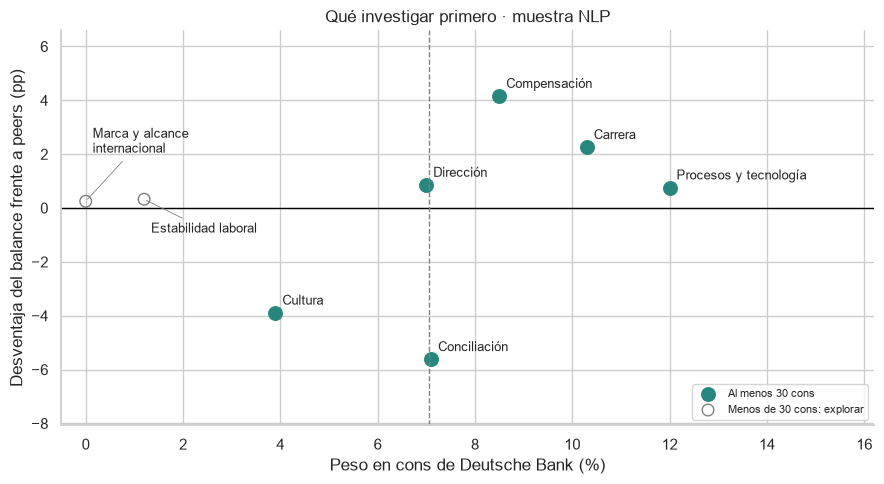

,pros_TARGET_%,balance_TARGET_pp,gap_pp,gap_periodo_común_pp
Cultura,20.8,16.9,3.90,-0.53
Conciliación,15.3,8.2,5.62,4.75


Las fortalezas con gap positivo pueden aportar mensajes de atracción si se respaldan con prácticas vigentes y testimonios voluntarios. Un balance todavía negativo matiza esa ventaja: ser menos desfavorable que los peers no equivale a una experiencia sin problemas. Las recomendaciones siguientes incorporan esa distinción y las limitaciones de cobertura.

In [17]:
prioridad = comparacion.loc[CATEGORIAS_NEGOCIO].copy()
prioridad['cons_n'] = contraste.n_categoría.astype(int)
prioridad['desventaja_pp'] = -prioridad.gap_pp
prioridad['puntuación_prioridad'] = prioridad['cons_TARGET_%'] * prioridad.desventaja_pp.clip(lower=0)
prioridad['gap_común_pp'] = gap_comun
prioridad = prioridad.sort_values('puntuación_prioridad', ascending=False)
tabla(prioridad[['cons_n', 'cons_TARGET_%', 'desventaja_pp', 'puntuación_prioridad', 'gap_común_pp']])
fig, ax = plt.subplots(figsize=(9, 5))
suficientes = prioridad.cons_n.ge(30)
ax.scatter(prioridad.loc[suficientes, 'cons_TARGET_%'], prioridad.loc[suficientes, 'desventaja_pp'],
           s=95, color='#27877F', label='Al menos 30 cons')
ax.scatter(prioridad.loc[~suficientes, 'cons_TARGET_%'], prioridad.loc[~suficientes, 'desventaja_pp'],
           s=70, facecolors='none', edgecolors='gray', label='Menos de 30 cons: explorar')
ax.legend(loc='lower right', fontsize=8)
for cat, r in prioridad.iterrows():
    desplazamiento = {'Marca y alcance internacional': (5, 35), 'Estabilidad laboral': (5, -24)}.get(cat, (5, 6))
    etiqueta = cat.replace('Marca y alcance internacional', 'Marca y alcance\ninternacional')
    ax.annotate(etiqueta, (r['cons_TARGET_%'], r.desventaja_pp), xytext=desplazamiento,
                textcoords='offset points', fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': 'gray', 'lw': .6} if abs(desplazamiento[1]) > 20 else None)
ax.axhline(0, color='black', lw=1)
ax.axvline(prioridad['cons_TARGET_%'].median(), color='gray', ls='--', lw=1)
ax.margins(.25)
ax.set_xlim(-.5, max(1, prioridad['cons_TARGET_%'].max()) * 1.35)
ax.set(xlabel='Peso en cons de Deutsche Bank (%)', ylabel='Desventaja del balance frente a peers (pp)',
       title='Qué investigar primero · muestra NLP')
plt.tight_layout(); plt.show()
fortalezas = comparacion.loc[CATEGORIAS_NEGOCIO].query('gap_pp > 0').sort_values('pros_TARGET_%', ascending=False)
fortalezas['gap_periodo_común_pp'] = gap_comun
tabla(fortalezas[['pros_TARGET_%', 'balance_TARGET_pp', 'gap_pp', 'gap_periodo_común_pp']])
narrar('Las fortalezas con gap positivo pueden aportar mensajes de atracción si se respaldan con prácticas '
       'vigentes y testimonios voluntarios. Un balance todavía negativo matiza esa ventaja: '
       'ser menos desfavorable que los peers no equivale a una experiencia sin problemas. '
       'Las recomendaciones siguientes incorporan esa distinción y las limitaciones de cobertura.')

In [18]:
# Propuestas seleccionadas para esta revisión; sus cifras se actualizan desde las tablas.
# Una edición de etiquetas obliga a revisar también el criterio editorial, no solo los números.
mapa_revisado_sha = '2ad522becf6f4639542dcc4b1c1916ea525caca2ec2a2aba89cdc86d94991104'
mapa_actual_sha = hashlib.sha256(json.dumps(TOPIC_A_CATEGORIA, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
assert mapa_actual_sha == mapa_revisado_sha, 'Etiquetas modificadas: revisar la selección de recomendaciones antes de cerrar el análisis.'
comp, carrera = comparacion.loc['Compensación'], comparacion.loc['Carrera']
direc, conc, cult = comparacion.loc['Dirección'], comparacion.loc['Conciliación'], comparacion.loc['Cultura']
qc, qd = contraste.loc['Compensación'], contraste.loc['Dirección']
qr, qp = contraste.loc['Carrera'], contraste.loc['Procesos y tecnología']
rd = retencion.loc['Dirección']
coincide_comp = qc.delta_rating < 0 and qc.delta_rec_pp < 0
lectura_comp = ('coincide con peor rating y recomendación' if coincide_comp
                else 'no coincide con peor rating y recomendación a la vez')
atraccion = (conc.gap_pp > 0 and gap_comun['Conciliación'] > 0 and conc.balance_TARGET_pp > 0)
assert comp.gap_pp < 0 and carrera.gap_pp < 0 and qd.delta_rating < 0 and atraccion, (
    'Ha cambiado la evidencia que motivó estas tres propuestas: revisar su selección.')
narrar(f'**Qué prioriza la evidencia.** Compensación reúne **{comp["cons_TARGET_%"]:.1f}%** de cons '
       f'y un gap de **{comp.gap_pp:+.2f} pp**; carrera, **{carrera["cons_TARGET_%"]:.1f}%** '
       f'y **{carrera.gap_pp:+.2f} pp**. La queja salarial **{lectura_comp}** y el contraste de rating '
       f'en carrera es de **{qr.delta_rating:+.2f}/5**: la matriz señala preguntas para investigar, no inversiones justificadas por sí solas.\n\n'
       f'Dirección añade una señal para retención: gap **{direc.gap_pp:+.2f} pp**, '
       f'**{gap_comun["Dirección"]:+.2f} pp** en el periodo común y rating **{qd.rating_cat:.2f}** '
       f'frente a **{qd.rating_resto:.2f}** en el resto. Procesos y tecnología recibe **{int(qp.n_categoría)}** cons, '
       f'pero su rating es **{qp.rating_cat:.2f}** frente a **{qp.rating_resto:.2f}**: el volumen no basta para situarlo primero.\n\n'
       f'Para atracción, **conciliación** mantiene gap positivo en ambas ventanas '
       f'(**{conc.gap_pp:+.2f}** y **{gap_comun["Conciliación"]:+.2f} pp**). '
       f'Cultura es frecuente en pros (**{cult["pros_TARGET_%"]:.1f}%**), pero su gap pasa de '
       f'**{cult.gap_pp:+.2f}** a **{gap_comun["Cultura"]:+.2f} pp**; no la presentamos como ventaja estable.')
recomendaciones = pd.DataFrame([
    {'Propuesta': '1. Diagnosticar la compensación',
     'Evidencia': f'{int(qc.n_categoría)} cons; gap {comp.gap_pp:+.2f} pp. Rating {qc.rating_cat:.2f} frente a {qc.rating_resto:.2f}: investigar por segmentos.',
     'Acción de RRHH': 'En 60 días, revisar bandas y progresión por puesto y país con datos internos y entrevistas. Ajustar solo donde se confirme desventaja.',
     'Indicador': '% de puestos y niveles revisados cuya banda queda por debajo de la referencia de mercado acordada. Medir base inicial antes de fijar meta.'},
    {'Propuesta': '2. Pilotar conversaciones de carrera',
     'Evidencia': f'Carrera: {int(qr.n_categoría)} cons, gap {carrera.gap_pp:+.2f} pp. Dirección: rating {qd.rating_cat:.2f}; cons en antiguos {rd["antiguos_TARGET_%"]:.1f}% frente a {rd["actuales_TARGET_%"]:.1f}% en actuales.',
     'Acción de RRHH': 'En dos equipos elegidos tras validar los temas, probar 90 días de conversaciones mensuales con el responsable, criterios de promoción escritos y plan de aprendizaje.',
     'Indicador': '% de participantes que conocen los criterios de progresión, con la misma pregunta al inicio y a los 90 días; informar de la tasa de respuesta.'},
    {'Propuesta': '3. Comunicar conciliación verificable',
     'Evidencia': f'Pros {conc["pros_TARGET_%"]:.1f}%, cons {conc["cons_TARGET_%"]:.1f}%; gap {conc.gap_pp:+.2f} pp, también positivo en fechas comunes.',
     'Acción de RRHH': 'Verificar qué opciones de flexibilidad siguen vigentes por puesto y comunicarlas en vacantes y entrevistas, con testimonios voluntarios.',
     'Indicador': '% de nuevas incorporaciones que a los 90 días confirma que la flexibilidad coincide con lo anunciado; desglosar por puesto y tasa de respuesta.'}
]).set_index('Propuesta')
display(Markdown(recomendaciones.to_markdown()))
narrar('Los plazos y pilotos son propuestas, no medidas ya implantadas, y los indicadores internos todavía no se han medido. '
       'Revisaremos con RRHH las fronteras cultura/conciliación, cultura/dirección, beneficios/permisos y los grupos mixtos. '
       'Si la validación cambia etiquetas o evidencia, revisaremos también estas tres acciones.')

**Qué prioriza la evidencia.** Compensación reúne **8.5%** de cons y un gap de **-4.15 pp**; carrera, **10.3%** y **-2.25 pp**. La queja salarial **no coincide con peor rating y recomendación a la vez** y el contraste de rating en carrera es de **-0.10/5**: la matriz señala preguntas para investigar, no inversiones justificadas por sí solas.

Dirección añade una señal para retención: gap **-0.85 pp**, **-3.85 pp** en el periodo común y rating **3.30** frente a **3.81** en el resto. Procesos y tecnología recibe **120** cons, pero su rating es **4.03** frente a **3.74**: el volumen no basta para situarlo primero.

Para atracción, **conciliación** mantiene gap positivo en ambas ventanas (**+5.62** y **+4.75 pp**). Cultura es frecuente en pros (**20.8%**), pero su gap pasa de **+3.90** a **-0.53 pp**; no la presentamos como ventaja estable.

| Propuesta                             | Evidencia                                                                                                 | Acción de RRHH                                                                                                                                                        | Indicador                                                                                                                                       |
|:--------------------------------------|:----------------------------------------------------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------|:------------------------------------------------------------------------------------------------------------------------------------------------|
| 1. Diagnosticar la compensación       | 85 cons; gap -4.15 pp. Rating 3.89 frente a 3.76: investigar por segmentos.                               | En 60 días, revisar bandas y progresión por puesto y país con datos internos y entrevistas. Ajustar solo donde se confirme desventaja.                                | % de puestos y niveles revisados cuya banda queda por debajo de la referencia de mercado acordada. Medir base inicial antes de fijar meta.      |
| 2. Pilotar conversaciones de carrera  | Carrera: 103 cons, gap -2.25 pp. Dirección: rating 3.30; cons en antiguos 9.6% frente a 5.4% en actuales. | En dos equipos elegidos tras validar los temas, probar 90 días de conversaciones mensuales con el responsable, criterios de promoción escritos y plan de aprendizaje. | % de participantes que conocen los criterios de progresión, con la misma pregunta al inicio y a los 90 días; informar de la tasa de respuesta.  |
| 3. Comunicar conciliación verificable | Pros 15.3%, cons 7.1%; gap +5.62 pp, también positivo en fechas comunes.                                  | Verificar qué opciones de flexibilidad siguen vigentes por puesto y comunicarlas en vacantes y entrevistas, con testimonios voluntarios.                              | % de nuevas incorporaciones que a los 90 días confirma que la flexibilidad coincide con lo anunciado; desglosar por puesto y tasa de respuesta. |

Los plazos y pilotos son propuestas, no medidas ya implantadas, y los indicadores internos todavía no se han medido. Revisaremos con RRHH las fronteras cultura/conciliación, cultura/dirección, beneficios/permisos y los grupos mixtos. Si la validación cambia etiquetas o evidencia, revisaremos también estas tres acciones.

**Alcance y límites.** Glassdoor recoge opiniones autoseleccionadas, no una muestra representativa de la plantilla. No disponemos de país o puesto para ajustar la mezcla de empleados. Los datos son históricos (2018–2023) y dos peers acaban antes; la comprobación del periodo común no resuelve toda la comparabilidad. La muestra aleatoria reduce coste, pero introduce incertidumbre: no interpretamos diferencias pequeñas como resultados concluyentes ni afirmamos significación estadística.

El sentimiento es binario y procede de otro dominio; hay errores, ambigüedad y recorte de textos. La detección de idioma es orientativa y existe un caso claramente alemán, por lo que no interpretamos individualmente su sentimiento. Los topics resumen un asunto dominante por texto, no todas sus menciones; las categorías propuestas necesitan validación humana y los textos sin clasificar pueden ocultar problemas. La revisión de ejemplos no es una medición de precisión. Los balances dependen de denominadores diferentes y son relativos, y las asociaciones con rating o recomendación no prueban causalidad. El siguiente paso proporcionado es validar las etiquetas con RRHH, contrastar los temas con encuestas y entrevistas internas y segmentar por puesto y país solo si conseguimos esos datos. No añadimos modelos predictivos ni métricas de clasificación supervisada: no responderían al encargo descriptivo.

In [19]:
# Comprobaciones de integridad y aritmética; fallan si se rompe la correspondencia o un denominador.
assert nlp.review_id.is_unique and nlp.index.equals(pd.Index(nlp.review_id, name='review_id'))
for lado, pct in [('pros', pct_pros), ('cons', pct_cons)]:
    assert np.allclose(pct.sum(axis=1), 100)
    assert ((pct >= 0) & (pct <= 100)).all().all()
    assert nlp[lado + '_sentimiento'].notna().sum() == nlp[lado + '_valido'].sum()
    assert nlp[lado + '_categoria'].notna().sum() == nlp[lado + '_valido'].sum()
assert np.allclose(balance, pct_pros - pct_cons)
assert np.allclose(gap, balance.loc[TARGET] - sum(balance.loc[p] for p in PEERS) / len(PEERS))
assert np.allclose(retencion['antiguos_peers_%'], pct_antiguos.loc[PEERS].sum() / len(PEERS))
for cat in CATEGORIAS:
    numerador = ((nlp.firm == TARGET) & nlp.cons_valido & (nlp.cons_categoria == cat)).sum()
    denominador = ((nlp.firm == TARGET) & nlp.cons_valido).sum()
    assert np.isclose(pct_cons.loc[TARGET, cat], porcentaje(numerador, denominador))
# Salidas locales de apoyo para revisar resultados; la notebook no depende de estas tablas.
for nombre, t in {'comparacion': comparacion, 'contraste': contraste, 'retencion': retencion,
                  'prioridad': prioridad, 'sensibilidad': sensibilidad}.items():
    t.to_csv(RUN / (nombre + '.csv'), encoding='utf-8-sig')
nlp.to_parquet(RUN / 'muestra_resultados.parquet', index=False)
narrar('**Validación completada:** identificadores, cobertura, sumas de porcentajes, balances, '
       'media simple de los cuatro peers y gaps coherentes. Caché identificada por `' + FIRMA[:12] + '`. '
       'Esto verifica la ejecución y la aritmética; las etiquetas de negocio y su interpretación requieren nuestra revisión conjunta.')
# Cero con denominador válido no equivale a ausencia de grupo.
sin_grupo = distribucion(nlp.iloc[:0], 'cons')
assert sin_grupo.isna().all().all()
assert pct_cons.loc[TARGET, 'Marca y alcance internacional'] == 0
for lado in ['pros', 'cons']:
    ids = nlp.loc[nlp[lado + '_valido'], 'review_id'].tolist()
    assert sentimientos[lado].index.tolist() == ids
    assert asignaciones[lado].index.tolist() == ids
    assert set(TOPIC_A_CATEGORIA[lado]) == set(asignaciones[lado].topic)
assert np.allclose(comparacion['pros_peers_%'], pct_pros.loc[PEERS].mean(skipna=False).reindex(comparacion.index))
assert np.allclose(comparacion['cons_peers_%'], pct_cons.loc[PEERS].mean(skipna=False).reindex(comparacion.index))
for estado, prefijo in [('Actual', 'actuales'), ('Antiguo', 'antiguos')]:
    denom = int(((nlp.firm == TARGET) & (nlp.situacion == estado) & nlp.cons_valido).sum())
    assert retencion[prefijo + '_TARGET_n'].sum() == denom
    assert np.allclose(retencion[prefijo + '_TARGET_%'], 100 * retencion[prefijo + '_TARGET_n'] / denom)
narrar('También se han comprobado los recuentos de retención y la distinción entre cero y datos ausentes. '
       'Las recomendaciones muestran valores tomados de las tablas de esta ejecución.')


**Validación completada:** identificadores, cobertura, sumas de porcentajes, balances, media simple de los cuatro peers y gaps coherentes. Caché identificada por `9401ac8c6ea5`. Esto verifica la ejecución y la aritmética; las etiquetas de negocio y su interpretación requieren nuestra revisión conjunta.

También se han comprobado los recuentos de retención y la distinción entre cero y datos ausentes. Las recomendaciones muestran valores tomados de las tablas de esta ejecución.

In [20]:
narrar(f'**Respuesta al encargo de RRHH.** La conciliación es la fortaleza comparativa más consistente de esta revisión '
       f'(gap **{gap["Conciliación"]:+.2f} pp**, también positivo en el periodo común). '
       'Compensación y carrera merecen investigación, pero las quejas salariales no bastan para justificar ajustes generales; '
       'las de dirección sí acompañan valoraciones más bajas. Priorizaríamos **diagnosticar compensación por segmentos, '
       'probar conversaciones de desarrollo con responsables y comunicar opciones de conciliación verificadas**. '
       'Son propuestas basadas en opiniones históricas, pendientes de validar las etiquetas y de contrastarlas con datos internos actuales.')

**Respuesta al encargo de RRHH.** La conciliación es la fortaleza comparativa más consistente de esta revisión (gap **+5.62 pp**, también positivo en el periodo común). Compensación y carrera merecen investigación, pero las quejas salariales no bastan para justificar ajustes generales; las de dirección sí acompañan valoraciones más bajas. Priorizaríamos **diagnosticar compensación por segmentos, probar conversaciones de desarrollo con responsables y comunicar opciones de conciliación verificadas**. Son propuestas basadas en opiniones históricas, pendientes de validar las etiquetas y de contrastarlas con datos internos actuales.